
# 10.5 Xu comparison for ENet zbig transformed validation

This notebook compares the tissue-level outputs from `7.5.test_enet_zbig.ipynb` against Xu `TableS6`.

It compares the same core metrics as notebook 10:

- Pearson / `r`
- RMSE
- MAE
- MSE

It also adds ENet zbig tissue-level cosine similarity from notebook 7.5. Xu `TableS6` usually does **not** contain cosine similarity, so the notebook reports and plots model cosine directly. If a cosine-like column is present in the Xu sheet, it will also compute `delta_cosine = model_cosine - xu_cosine`.


In [1]:

from pathlib import Path
import os
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.dpi": 130,
    "savefig.dpi": 180,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold",
    "axes.labelsize": 10,
})

CWD = Path.cwd().resolve()
PROJECT_MARKERS = [
    "results_comparison_enet_zbig_transformed",
    "val_data_enet_zbig",
    "processed_data",
    "res_enet_zbig",
    "Table0_S1-S8_Combined20220114.xlsx",
]

def _candidate_score(path: Path) -> int:
    return sum((path / marker).exists() for marker in PROJECT_MARKERS)

_project_candidates = []
for p in [CWD, *CWD.parents]:
    if p.exists() and p not in _project_candidates:
        _project_candidates.append(p)
ROOT_DIR = max(_project_candidates, key=_candidate_score)

RESULTS_DIR = ROOT_DIR / "results_comparison_enet_zbig_transformed"
METRICS_TISSUE_TABLES6_CSV = RESULTS_DIR / "eval_metrics_by_tissue_tableS6_format.csv"
METRICS_TISSUE_CSV = RESULTS_DIR / "eval_metrics_by_tissue.csv"
ENET_ZBIG_TABLES6_CSV = RESULTS_DIR / "enet_zbig_tissue_metrics_xu_format.csv"

# Optional hard override if needed.
# MANUAL_XU_XLSX_PATH = r"C:\Users\hp\Desktop\new_pRNA\Table0_S1-S8_Combined20220114.xlsx"
MANUAL_XU_XLSX_PATH = None

OUT_DIR = ROOT_DIR / "xu_enet_zbig_comparison_outputs"
OUT_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR = OUT_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

TABLES6_COLUMNS = [
    "ShortName", "common", "totalRNA", "totalprotein", "pearson", "spearman",
    "tissue", "samples", "platform", "complexity_RNA", "complexity_protein",
    "mae", "r", "rmse", "tissue specific protein", "tissue_specific_protein",
]

print("Current working directory:", CWD)
print("Detected project root:", ROOT_DIR)
print("7.5 results directory:", RESULTS_DIR)
print("Main 7.5 tissue file:", METRICS_TISSUE_TABLES6_CSV)
print("Output folder:", OUT_DIR)


Current working directory: C:\Users\hp\Desktop\new_pRNA\notebooks2
Detected project root: C:\Users\hp\Desktop\new_pRNA
7.5 results directory: C:\Users\hp\Desktop\new_pRNA\results_comparison_enet_zbig_transformed
Main 7.5 tissue file: C:\Users\hp\Desktop\new_pRNA\results_comparison_enet_zbig_transformed\eval_metrics_by_tissue_tableS6_format.csv
Output folder: C:\Users\hp\Desktop\new_pRNA\xu_enet_zbig_comparison_outputs


## 1. Locate and load Xu TableS6

In [2]:

def find_xu_excel():
    explicit_candidates = []
    if MANUAL_XU_XLSX_PATH:
        explicit_candidates.append(Path(MANUAL_XU_XLSX_PATH).expanduser())
    if os.environ.get("XU_XLSX_PATH"):
        explicit_candidates.append(Path(os.environ["XU_XLSX_PATH"]).expanduser())

    likely_names = ["Table0_S1-S8_Combined20220114.xlsx", "Table0_S1-S8_Combined20220114.xls"]
    search_roots = []
    for p in [ROOT_DIR, CWD, CWD.parent, ROOT_DIR.parent]:
        if p.exists() and p not in search_roots:
            search_roots.append(p)

    candidates = []
    candidates.extend(explicit_candidates)
    for base in search_roots:
        for name in likely_names:
            candidates.append(base / name)

    checked = []
    seen = set()
    for p in candidates:
        try:
            rp = Path(p).resolve()
        except Exception:
            continue
        if rp in seen or not rp.exists():
            continue
        seen.add(rp)
        try:
            xl = pd.ExcelFile(rp)
            checked.append((rp, xl.sheet_names))
            if "TableS6" in xl.sheet_names:
                return rp, checked
        except Exception as exc:
            checked.append((rp, f"unreadable: {exc}"))

    recursive = []
    for base in search_roots:
        try:
            recursive.extend(base.rglob("*.xlsx"))
            recursive.extend(base.rglob("*.xls"))
        except Exception:
            pass
    recursive = sorted(set(recursive), key=lambda p: ("combined20220114" not in p.name.lower(), "table0" not in p.name.lower(), len(str(p))))
    for p in recursive:
        try:
            rp = p.resolve()
        except Exception:
            continue
        if rp in seen:
            continue
        seen.add(rp)
        try:
            xl = pd.ExcelFile(rp)
            checked.append((rp, xl.sheet_names))
            if "TableS6" in xl.sheet_names:
                return rp, checked
        except Exception as exc:
            checked.append((rp, f"unreadable: {exc}"))
    return None, checked

XLSX_PATH, XLSX_CHECKED = find_xu_excel()
if XLSX_PATH is None:
    print("Xu Excel file was not found. Checked examples:")
    for path, sheets in XLSX_CHECKED[:10]:
        print("-", path, "->", sheets)
    raise FileNotFoundError("Put Table0_S1-S8_Combined20220114.xlsx in the project root or set MANUAL_XU_XLSX_PATH.")

print("Xu Excel file:", XLSX_PATH)
xl = pd.ExcelFile(XLSX_PATH)
print("Sheets:", xl.sheet_names)

xu_raw = pd.read_excel(XLSX_PATH, sheet_name="TableS6")
xu = xu_raw.copy()
xu.columns = [str(c).strip() for c in xu.columns]
if "ShortName" not in xu.columns:
    raise ValueError("TableS6 does not contain the expected ShortName column.")

# Keep all columns first so cosine-like columns are not lost if present.
for c in ["common", "totalRNA", "totalprotein", "pearson", "spearman", "samples", "mae", "r", "rmse", "tissue_specific_protein"]:
    if c in xu.columns:
        xu[c] = pd.to_numeric(xu[c], errors="coerce")

xu = xu.dropna(subset=["ShortName"]).copy()
xu["xu_dataset"] = xu["ShortName"].astype(str)
xu["xu_proxy_pearson"] = xu.get("pearson", np.nan)
xu["xu_proxy_spearman"] = xu.get("spearman", np.nan)
xu["xu_r"] = xu.get("r", np.nan)
xu["xu_mae"] = xu.get("mae", np.nan)
xu["xu_rmse"] = xu.get("rmse", np.nan)
xu["xu_mse"] = xu["xu_rmse"] ** 2

xu_cosine_candidates = [c for c in xu.columns if c.lower().replace(" ", "_") in {"cosine", "cosine_similarity", "cos", "cos_sim"}]
if xu_cosine_candidates:
    xu["xu_cosine"] = pd.to_numeric(xu[xu_cosine_candidates[0]], errors="coerce")
    print("Xu cosine-like column found:", xu_cosine_candidates[0])
else:
    xu["xu_cosine"] = np.nan
    print("Xu TableS6 has no cosine-like column. Cosine will be reported for the ENet model only.")

print("Xu TableS6 rows:", xu.shape[0])
display(xu[[c for c in TABLES6_COLUMNS + ["xu_r", "xu_rmse", "xu_mae", "xu_cosine"] if c in xu.columns]].head(10))


Xu Excel file: C:\Users\hp\Desktop\new_pRNA\Table0_S1-S8_Combined20220114.xlsx
Sheets: ['TableS1', 'TableS2', 'TableS3', 'TableS4', 'TableS5', 'TableS6', 'TableS7', 'TableS8']
Xu TableS6 has no cosine-like column. Cosine will be reported for the ENet model only.
Xu TableS6 rows: 20


,ShortName,common,totalRNA,totalprotein,pearson,spearman,tissue,samples,platform,complexity_RNA,complexity_protein,mae,r,rmse,tissue specific protein,tissue_specific_protein,xu_r,xu_rmse,xu_mae,xu_cosine
0,CO_labelfree,2113,14959,2244,0.229183,0.235372,colon,86,labelfree,0.393815,0.363863,0.751304,0.259475,0.956563,757,757,0.259475,0.956563,0.751304,NaN
1,BN_labelfree,4234,14408,4385,0.151748,0.152212,brain,71,labelfree,0.717820,0.442767,0.680979,0.397859,0.880700,1850,1850,0.397859,0.880700,0.680979,NaN
2,PR_labelfree,3445,21601,3537,0.226986,0.224086,prostate,65,labelfree,0.449804,0.281128,0.745326,0.297630,0.932632,1060,1060,0.297630,0.932632,0.745326,NaN
3,LV_labelfree,2315,14180,2354,0.412494,0.386321,liver,62,labelfree,0.434155,0.435965,0.641711,0.509291,0.813337,757,757,0.509291,0.813337,0.641711,NaN
4,LU_labelfree,2209,16597,2272,0.118115,0.104513,lung,76,labelfree,0.525222,0.515724,0.770595,0.326919,0.958027,712,712,0.326919,0.958027,0.770595,NaN
5,LV_tmt,6195,12559,6472,0.448624,0.390871,liver,318,tmt,0.578292,0.611368,0.529236,0.697328,0.694758,2067,2067,0.697328,0.694758,0.529236,NaN
6,CO_tmt,4201,12932,4375,0.289840,0.280570,colon,95,tmt,0.446393,0.385841,0.752258,0.327762,0.949505,1392,1392,0.327762,0.949505,0.752258,NaN
7,RC_tmt,6933,14636,7146,0.510334,0.531295,renal,185,tmt,0.598990,0.637353,0.510158,0.734394,0.640897,2292,2292,0.734394,0.640897,0.510158,NaN
8,PBN_tmt,6184,18197,6425,0.460076,0.428887,pedbrain,188,tmt,0.628463,0.612700,0.567398,0.654054,0.728755,2313,2313,0.654054,0.728755,0.567398,NaN
9,BR_tmt,5698,10163,7581,0.443950,0.449147,breast,122,tmt,0.357786,0.385439,0.628184,0.553957,0.803906,2450,2450,0.553957,0.803906,0.628184,NaN


## 2. Load tissue metrics exported by notebook 7.5

In [3]:

def load_enet_zbig_tissue_tables6():
    checked = []
    if METRICS_TISSUE_TABLES6_CSV.exists():
        return pd.read_csv(METRICS_TISSUE_TABLES6_CSV), METRICS_TISSUE_TABLES6_CSV, checked
    checked.append(METRICS_TISSUE_TABLES6_CSV)

    if ENET_ZBIG_TABLES6_CSV.exists():
        return pd.read_csv(ENET_ZBIG_TABLES6_CSV), ENET_ZBIG_TABLES6_CSV, checked + [ENET_ZBIG_TABLES6_CSV]

    per_source = sorted(RESULTS_DIR.glob("*__eval_metrics_by_tissue_tableS6_format.csv"))
    if per_source:
        frames = []
        for p in per_source:
            try:
                frames.append(pd.read_csv(p))
            except Exception as exc:
                print(f"Skipping unreadable tissue file {p}: {exc}")
        if frames:
            return pd.concat(frames, ignore_index=True, sort=False), "per-source TableS6 files", checked + per_source

    raise FileNotFoundError(
        "No tissue TableS6-format metrics from notebook 7.5 were found. Run 7.5.test_enet_zbig.ipynb first. Checked: "
        + ", ".join(str(p) for p in checked + [ENET_ZBIG_TABLES6_CSV])
    )

model_raw, model_source_path, checked = load_enet_zbig_tissue_tables6()
model = model_raw.copy()
model.columns = [str(c).strip() for c in model.columns]

for c in ["common", "totalRNA", "totalprotein", "pearson", "spearman", "samples", "mae", "r", "rmse", "mse", "test_r2", "test_mse", "test_cosine_similarity", "cosine", "n_prediction_pairs", "n_samples", "n_proteins"]:
    if c in model.columns:
        model[c] = pd.to_numeric(model[c], errors="coerce")

if "mse" not in model.columns:
    model["mse"] = np.nan
if "test_mse" in model.columns:
    model["model_mse"] = model["test_mse"]
else:
    model["model_mse"] = model["mse"].where(model["mse"].notna(), model["rmse"] ** 2)

cos_cols = [c for c in ["test_cosine_similarity", "cosine", "cosine_similarity", "median_protein_cosine"] if c in model.columns]
if cos_cols:
    model["model_cosine"] = pd.to_numeric(model[cos_cols[0]], errors="coerce")
    print("Using model cosine column:", cos_cols[0])
else:
    model["model_cosine"] = np.nan
    print("No model cosine column was found. Re-run 7.5 after updating it.")

if "source_folder" not in model.columns:
    model["source_folder"] = model.get("source", "enet_zbig")
if "run_label" not in model.columns:
    metadata_cols = [c for c in ["source_folder", "model_family", "normalization", "grid_preset", "select_k"] if c in model.columns]
    model["run_label"] = model[metadata_cols].astype(str).agg(" | ".join, axis=1) if metadata_cols else "enet_zbig"

model["model_id"] = model["run_label"].astype(str)
if "source_folder" in model.columns:
    model["model_id"] = model["source_folder"].astype(str) + " :: " + model["model_id"]

print("Loaded ENet zbig tissue metrics from:", model_source_path)
print("Rows:", model.shape[0])
print("Model runs:", model["model_id"].nunique())
display(model[[c for c in TABLES6_COLUMNS + ["model_id", "test_r2", "test_mse", "model_cosine", "test_cosine_similarity", "n_prediction_pairs"] if c in model.columns]].head(20))


Using model cosine column: test_cosine_similarity
Loaded ENet zbig tissue metrics from: C:\Users\hp\Desktop\new_pRNA\results_comparison_enet_zbig_transformed\eval_metrics_by_tissue_tableS6_format.csv
Rows: 20
Model runs: 1


,ShortName,common,totalRNA,totalprotein,pearson,spearman,tissue,samples,platform,complexity_RNA,...,r,rmse,tissue specific protein,tissue_specific_protein,model_id,test_r2,test_mse,model_cosine,test_cosine_similarity,n_prediction_pairs
0,CO_labelfree,2172,14947,2172,0.076525,0.073001,colon,86,labelfree,NaN,...,0.076525,1.049127,2172,2172,res_enet_zbig :: res_enet_zbig | zscore | fast...,-0.470979,1.100666,0.033663,0.033663,186792
1,BN_labelfree,2172,14947,2172,0.090345,0.164570,brain,71,labelfree,NaN,...,0.090345,16.007260,2172,2172,res_enet_zbig :: res_enet_zbig | zscore | fast...,-326.931905,256.232383,0.069302,0.069302,154212
2,PR_labelfree,2172,14947,2172,0.072682,0.049750,prostate,65,labelfree,NaN,...,0.072682,1.236679,2172,2172,res_enet_zbig :: res_enet_zbig | zscore | fast...,-0.592105,1.529376,0.098487,0.098487,141180
3,LV_labelfree,2172,14947,2172,0.074402,0.141820,liver,62,labelfree,NaN,...,0.074402,189.143032,2172,2172,res_enet_zbig :: res_enet_zbig | zscore | fast...,-24868.878900,35775.086505,0.073428,0.073428,134664
4,LU_labelfree,2172,14947,2172,0.072665,0.041586,lung,76,labelfree,NaN,...,0.072665,1.173005,2172,2172,res_enet_zbig :: res_enet_zbig | zscore | fast...,-0.149907,1.375940,0.072110,0.072110,165072
5,LV_tmt,4450,15001,4450,0.207272,0.202334,liver,318,tmt,NaN,...,0.207272,2.731027,4450,4450,res_enet_zbig :: res_enet_zbig | zscore | fast...,-9.727701,7.458511,-0.407489,-0.407489,1415100
6,CO_tmt,4450,15001,4450,0.024097,0.017508,colon,95,tmt,NaN,...,0.024097,2.874413,4450,4450,res_enet_zbig :: res_enet_zbig | zscore | fast...,-10.541266,8.262249,-0.511136,-0.511136,422750
7,RC_tmt,4450,15001,4450,-0.012724,-0.159839,renal,185,tmt,NaN,...,-0.012724,78.806317,4450,4450,res_enet_zbig :: res_enet_zbig | zscore | fast...,-1967.504766,6210.435668,0.009247,0.009247,823250
8,PBN_tmt,4450,15001,4450,0.132318,0.111288,pedbrain,188,tmt,NaN,...,0.132318,2.102266,4450,4450,res_enet_zbig :: res_enet_zbig | zscore | fast...,-4.060234,4.419522,0.332569,0.332569,836600
9,BR_tmt,4450,15001,4450,0.183701,0.171186,breast,122,tmt,NaN,...,0.183701,2.070674,4450,4450,res_enet_zbig :: res_enet_zbig | zscore | fast...,-1.118999,4.287689,0.350591,0.350591,542900


## 3. Harmonize tissue/platform keys and merge

In [4]:

TISSUE_NAME_MAP = {
    "co": "colon", "colon": "colon", "colorectal": "colon", "crc": "colon",
    "bn": "brain", "brain": "brain",
    "pr": "prostate", "prostate": "prostate",
    "lv": "liver", "li": "liver", "liver": "liver",
    "lu": "lung", "lung": "lung", "lu1": "lung_1", "lung1": "lung_1", "lu_1": "lung_1", "lung_1": "lung_1",
    "lu2": "lung_2", "lung2": "lung_2", "lu_2": "lung_2", "lung_2": "lung_2",
    "lu3": "lung_3", "lung3": "lung_3", "lu_3": "lung_3", "lung_3": "lung_3",
    "rc": "renal", "renal": "renal", "kidney": "renal",
    "pbn": "pedbrain", "pedbrain": "pedbrain", "pediatricbrain": "pedbrain",
    "br": "breast", "breast": "breast",
    "ec": "uterus", "uterus": "uterus", "endometrium": "uterus", "endometrial": "uterus",
    "hn": "headneck", "headneck": "headneck", "headandneck": "headneck",
    "pa": "pancrea", "pancrea": "pancrea", "pancreas": "pancrea", "pancreatic": "pancrea",
    "ov": "ovary", "ovary": "ovary", "ovarian": "ovary",
    "gc": "stomach", "stomach": "stomach", "gastric": "stomach",
}

PLATFORM_NAME_MAP = {
    "labelfree": "labelfree", "label_free": "labelfree", "label-free": "labelfree", "lf": "labelfree",
    "itraq": "itraq", "tmt": "tmt",
}

# Manual maps remain here for quick editing if unmatched diagnostics show a problem.
MANUAL_TISSUE_MAP = {}
MANUAL_PLATFORM_MAP = {}
MANUAL_SHORTNAME_MAP = {}


def norm_text(x):
    return re.sub(r"[^a-z0-9]+", "", str(x).strip().lower())


def harmonize_tissue(x):
    raw = str(x).strip()
    compact = norm_text(raw)
    if raw in MANUAL_TISSUE_MAP:
        return MANUAL_TISSUE_MAP[raw]
    if compact in MANUAL_TISSUE_MAP:
        return MANUAL_TISSUE_MAP[compact]
    return TISSUE_NAME_MAP.get(compact, compact or "unknown")


def harmonize_platform(x):
    raw = str(x).strip()
    compact = norm_text(raw)
    if raw in MANUAL_PLATFORM_MAP:
        return MANUAL_PLATFORM_MAP[raw]
    if compact in MANUAL_PLATFORM_MAP:
        return MANUAL_PLATFORM_MAP[compact]
    return PLATFORM_NAME_MAP.get(compact, compact)


def harmonize_shortname(x):
    raw = str(x).strip()
    if raw in MANUAL_SHORTNAME_MAP:
        return MANUAL_SHORTNAME_MAP[raw]
    return raw.lower()

# Xu keys.
xu["tissue_key"] = xu["tissue"].map(harmonize_tissue)
xu["platform_key"] = xu["platform"].map(harmonize_platform)
xu["shortname_key"] = xu["ShortName"].map(harmonize_shortname)
xu["tissue_platform_key"] = xu["tissue_key"] + "__" + xu["platform_key"]

# Model keys.
model["tissue_key"] = model["tissue"].map(harmonize_tissue)
model["platform_key"] = model["platform"].map(harmonize_platform)
model["shortname_key"] = model["ShortName"].map(harmonize_shortname) if "ShortName" in model.columns else ""
model["tissue_platform_key"] = model["tissue_key"] + "__" + model["platform_key"]

# Prefer exact ShortName matching. Fallback to tissue/platform.
model_exact_keys = set(model["shortname_key"].dropna())
xu["join_key"] = np.where(xu["shortname_key"].isin(model_exact_keys), "short__" + xu["shortname_key"], "tp__" + xu["tissue_platform_key"])
model["join_key"] = np.where(model["shortname_key"].isin(set(xu["shortname_key"].dropna())), "short__" + model["shortname_key"], "tp__" + model["tissue_platform_key"])

sort_cols = [c for c in ["n_prediction_pairs", "samples"] if c in model.columns]
if sort_cols:
    model_unique = model.sort_values(sort_cols, ascending=[False] * len(sort_cols)).drop_duplicates(["join_key", "model_id"], keep="first").copy()
else:
    model_unique = model.drop_duplicates(["join_key", "model_id"], keep="first").copy()

comparison = xu.merge(model_unique, on="join_key", how="left", suffixes=("_xu", "_model"))

comparison["model_r"] = pd.to_numeric(comparison.get("r_model", comparison.get("r", np.nan)), errors="coerce")
comparison["model_mae"] = pd.to_numeric(comparison.get("mae_model", comparison.get("mae", np.nan)), errors="coerce")
comparison["model_rmse"] = pd.to_numeric(comparison.get("rmse_model", comparison.get("rmse", np.nan)), errors="coerce")
comparison["model_mse"] = pd.to_numeric(comparison.get("model_mse", comparison.get("mse", comparison["model_rmse"] ** 2)), errors="coerce")
comparison["model_r2"] = pd.to_numeric(comparison.get("test_r2", np.nan), errors="coerce")
comparison["model_cosine"] = pd.to_numeric(comparison.get("model_cosine", comparison.get("test_cosine_similarity", comparison.get("cosine", np.nan))), errors="coerce")
comparison["xu_cosine"] = pd.to_numeric(comparison.get("xu_cosine", np.nan), errors="coerce")

for left, right, delta in [
    ("model_r", "xu_r", "delta_r"),
    ("model_rmse", "xu_rmse", "delta_rmse"),
    ("model_mae", "xu_mae", "delta_mae"),
    ("model_mse", "xu_mse", "delta_mse"),
    ("model_cosine", "xu_cosine", "delta_cosine"),
]:
    comparison[delta] = comparison[left] - comparison[right]

matched = comparison.dropna(subset=["model_r"]).copy()
unmatched_xu = xu[~xu["join_key"].isin(model_unique["join_key"])].copy()
unmatched_model = model_unique[~model_unique["join_key"].isin(xu["join_key"])].copy()

print(f"Matched Xu rows after expansion over ENet model runs: {len(matched):,}")
print(f"Unique Xu tissue/platform rows matched: {matched['ShortName_xu'].nunique() if 'ShortName_xu' in matched.columns else 0} / {len(xu)}")
print(f"ENet model runs compared: {matched['model_id'].nunique() if 'model_id' in matched.columns else 0}")
print(f"Unmatched Xu rows: {len(unmatched_xu)}")
print(f"Unmatched ENet tissue/model rows: {len(unmatched_model)}")

show_cols = [c for c in [
    "ShortName_xu", "tissue_xu", "platform_xu", "model_id", "source_folder", "run_label",
    "samples_xu", "samples_model", "common_xu", "common_model", "n_prediction_pairs",
    "model_r", "xu_r", "delta_r", "model_r2", "model_rmse", "xu_rmse", "delta_rmse",
    "model_mae", "xu_mae", "delta_mae", "model_cosine", "xu_cosine", "delta_cosine",
] if c in comparison.columns]

display(matched[show_cols].sort_values([c for c in ["model_id", "platform_xu", "tissue_xu"] if c in matched.columns]).head(40))


Matched Xu rows after expansion over ENet model runs: 20
Unique Xu tissue/platform rows matched: 20 / 20
ENet model runs compared: 1
Unmatched Xu rows: 0
Unmatched ENet tissue/model rows: 0


,ShortName_xu,tissue_xu,platform_xu,model_id,source_folder,run_label,samples_xu,samples_model,common_xu,common_model,...,model_r2,model_rmse,xu_rmse,delta_rmse,model_mae,xu_mae,delta_mae,model_cosine,xu_cosine,delta_cosine
17,BR_itraq,breast,itraq,res_enet_zbig :: res_enet_zbig | zscore | fast...,res_enet_zbig,res_enet_zbig | zscore | fast | k5000,77,77,6769,3725,...,-5.903646,1.511964,0.880977,0.630987,1.221703,0.692841,0.528861,0.087467,NaN,NaN
18,OV_itraq,ovary,itraq,res_enet_zbig :: res_enet_zbig | zscore | fast...,res_enet_zbig,res_enet_zbig | zscore | fast | k5000,119,119,4056,3725,...,-42.116769,3.588176,0.833745,2.754431,2.873363,0.640151,2.233212,0.029066,NaN,NaN
19,GC_itraq,stomach,itraq,res_enet_zbig :: res_enet_zbig | zscore | fast...,res_enet_zbig,res_enet_zbig | zscore | fast | k5000,80,80,4732,3725,...,-7.353958,1.623912,0.938360,0.685552,1.308446,0.741859,0.566587,0.016214,NaN,NaN
1,BN_labelfree,brain,labelfree,res_enet_zbig :: res_enet_zbig | zscore | fast...,res_enet_zbig,res_enet_zbig | zscore | fast | k5000,71,71,4234,2172,...,-326.931905,16.007260,0.880700,15.126560,6.699795,0.680979,6.018816,0.069302,NaN,NaN
0,CO_labelfree,colon,labelfree,res_enet_zbig :: res_enet_zbig | zscore | fast...,res_enet_zbig,res_enet_zbig | zscore | fast | k5000,86,86,2113,2172,...,-0.470979,1.049127,0.956563,0.092563,0.841370,0.751304,0.090067,0.033663,NaN,NaN
3,LV_labelfree,liver,labelfree,res_enet_zbig :: res_enet_zbig | zscore | fast...,res_enet_zbig,res_enet_zbig | zscore | fast | k5000,62,62,2315,2172,...,-24868.878900,189.143032,0.813337,188.329695,60.788673,0.641711,60.146962,0.073428,NaN,NaN
4,LU_labelfree,lung,labelfree,res_enet_zbig :: res_enet_zbig | zscore | fast...,res_enet_zbig,res_enet_zbig | zscore | fast | k5000,76,76,2209,2172,...,-0.149907,1.173005,0.958027,0.214978,0.954915,0.770595,0.184320,0.072110,NaN,NaN
2,PR_labelfree,prostate,labelfree,res_enet_zbig :: res_enet_zbig | zscore | fast...,res_enet_zbig,res_enet_zbig | zscore | fast | k5000,65,65,3445,2172,...,-0.592105,1.236679,0.932632,0.304047,0.991153,0.745326,0.245826,0.098487,NaN,NaN
16,BN_tmt,brain,tmt,res_enet_zbig :: res_enet_zbig | zscore | fast...,res_enet_zbig,res_enet_zbig | zscore | fast | k5000,108,108,8565,4450,...,-25.193366,4.513726,0.667599,3.846128,3.852956,0.530038,3.322918,-0.452039,NaN,NaN
9,BR_tmt,breast,tmt,res_enet_zbig :: res_enet_zbig | zscore | fast...,res_enet_zbig,res_enet_zbig | zscore | fast | k5000,122,122,5698,4450,...,-1.118999,2.070674,0.803906,1.266768,1.701057,0.628184,1.072873,0.350591,NaN,NaN


## 4. Summary statistics

In [5]:

if matched.empty:
    raise ValueError("No matched rows were found. Inspect unmatched diagnostics below and edit manual maps if needed.")

has_xu_cosine = matched["xu_cosine"].notna().any() if "xu_cosine" in matched.columns else False

summary_rows = []
for model_id, sub in matched.groupby("model_id", dropna=False):
    row = {
        "model_id": model_id,
        "source_folder": sub["source_folder"].dropna().iloc[0] if "source_folder" in sub.columns and sub["source_folder"].notna().any() else np.nan,
        "run_label": sub["run_label"].dropna().iloc[0] if "run_label" in sub.columns and sub["run_label"].notna().any() else model_id,
        "n_matched_rows": len(sub),
        "n_xu_datasets": sub["ShortName_xu"].nunique() if "ShortName_xu" in sub.columns else np.nan,
        "mean_model_r": sub["model_r"].mean(),
        "mean_xu_r": sub["xu_r"].mean(),
        "mean_delta_r": sub["delta_r"].mean(),
        "median_delta_r": sub["delta_r"].median(),
        "n_model_r_better_or_equal": int((sub["delta_r"] >= 0).sum()),
        "mean_model_rmse": sub["model_rmse"].mean(),
        "mean_xu_rmse": sub["xu_rmse"].mean(),
        "mean_delta_rmse": sub["delta_rmse"].mean(),
        "median_delta_rmse": sub["delta_rmse"].median(),
        "n_model_rmse_better_or_equal": int((sub["delta_rmse"] <= 0).sum()),
        "mean_model_mae": sub["model_mae"].mean(),
        "mean_xu_mae": sub["xu_mae"].mean(),
        "mean_delta_mae": sub["delta_mae"].mean(),
        "median_delta_mae": sub["delta_mae"].median(),
        "n_model_mae_better_or_equal": int((sub["delta_mae"] <= 0).sum()),
        "mean_model_mse": sub["model_mse"].mean(),
        "mean_xu_mse": sub["xu_mse"].mean(),
        "mean_delta_mse": sub["delta_mse"].mean(),
        "median_delta_mse": sub["delta_mse"].median(),
        "n_model_mse_better_or_equal": int((sub["delta_mse"] <= 0).sum()),
        "mean_model_cosine": sub["model_cosine"].mean(),
        "median_model_cosine": sub["model_cosine"].median(),
    }
    if has_xu_cosine:
        row.update({
            "mean_xu_cosine": sub["xu_cosine"].mean(),
            "mean_delta_cosine": sub["delta_cosine"].mean(),
            "median_delta_cosine": sub["delta_cosine"].median(),
            "n_model_cosine_better_or_equal": int((sub["delta_cosine"] >= 0).sum()),
        })
    summary_rows.append(row)

comparison_summary = pd.DataFrame(summary_rows).sort_values(["median_delta_r", "mean_delta_r"], ascending=False).reset_index(drop=True)
print("Model-level comparison summary. Higher r/cosine is better; lower RMSE/MAE/MSE is better.")
if not has_xu_cosine:
    print("Cosine note: Xu TableS6 has no cosine column, so model cosine is summarized without a Xu delta.")
display(comparison_summary)

best_by_r = matched.sort_values("delta_r", ascending=False).groupby("ShortName_xu", as_index=False).head(1)
best_by_rmse = matched.sort_values("delta_rmse", ascending=True).groupby("ShortName_xu", as_index=False).head(1)
best_by_cosine = matched.sort_values("model_cosine", ascending=False).groupby("ShortName_xu", as_index=False).head(1)

print("Best ENet zbig model/run per Xu row by Pearson/r delta:")
display(best_by_r[[c for c in ["ShortName_xu", "tissue_xu", "platform_xu", "model_id", "model_r", "xu_r", "delta_r", "model_r2", "model_cosine"] if c in best_by_r.columns]].sort_values("delta_r", ascending=False))

print("Best ENet zbig model/run per Xu row by RMSE delta:")
display(best_by_rmse[[c for c in ["ShortName_xu", "tissue_xu", "platform_xu", "model_id", "model_rmse", "xu_rmse", "delta_rmse", "model_r", "model_cosine"] if c in best_by_rmse.columns]].sort_values("delta_rmse", ascending=True))

print("Best ENet zbig model/run per Xu row by model cosine similarity:")
display(best_by_cosine[[c for c in ["ShortName_xu", "tissue_xu", "platform_xu", "model_id", "model_cosine", "model_r", "xu_r", "delta_r"] if c in best_by_cosine.columns]].sort_values("model_cosine", ascending=False))


Model-level comparison summary. Higher r/cosine is better; lower RMSE/MAE/MSE is better.
Cosine note: Xu TableS6 has no cosine column, so model cosine is summarized without a Xu delta.


,model_id,source_folder,run_label,n_matched_rows,n_xu_datasets,mean_model_r,mean_xu_r,mean_delta_r,median_delta_r,n_model_r_better_or_equal,...,mean_delta_mae,median_delta_mae,n_model_mae_better_or_equal,mean_model_mse,mean_xu_mse,mean_delta_mse,median_delta_mse,n_model_mse_better_or_equal,mean_model_cosine,median_model_cosine
0,res_enet_zbig :: res_enet_zbig | zscore | fast...,res_enet_zbig,res_enet_zbig | zscore | fast | k5000,20,20,0.055392,0.507679,-0.452287,-0.424343,0,...,5.923095,1.85827,0,2119.716462,0.674025,2119.042437,7.168256,0,0.031397,0.070706


Best ENet zbig model/run per Xu row by Pearson/r delta:


,ShortName_xu,tissue_xu,platform_xu,model_id,model_r,xu_r,delta_r,model_r2,model_cosine
12,LU_2_tmt,lung,tmt,res_enet_zbig :: res_enet_zbig | zscore | fast...,0.159363,0.290881,-0.131518,-1.084359,0.339866
0,CO_labelfree,colon,labelfree,res_enet_zbig :: res_enet_zbig | zscore | fast...,0.076525,0.259475,-0.182950,-0.470979,0.033663
2,PR_labelfree,prostate,labelfree,res_enet_zbig :: res_enet_zbig | zscore | fast...,0.072682,0.297630,-0.224947,-0.592105,0.098487
19,GC_itraq,stomach,itraq,res_enet_zbig :: res_enet_zbig | zscore | fast...,0.071668,0.324377,-0.252709,-7.353958,0.016214
4,LU_labelfree,lung,labelfree,res_enet_zbig :: res_enet_zbig | zscore | fast...,0.072665,0.326919,-0.254254,-0.149907,0.072110
6,CO_tmt,colon,tmt,res_enet_zbig :: res_enet_zbig | zscore | fast...,0.024097,0.327762,-0.303665,-10.541266,-0.511136
1,BN_labelfree,brain,labelfree,res_enet_zbig :: res_enet_zbig | zscore | fast...,0.090345,0.397859,-0.307514,-326.931905,0.069302
17,BR_itraq,breast,itraq,res_enet_zbig :: res_enet_zbig | zscore | fast...,0.104376,0.432062,-0.327686,-5.903646,0.087467
9,BR_tmt,breast,tmt,res_enet_zbig :: res_enet_zbig | zscore | fast...,0.183701,0.553957,-0.370256,-1.118999,0.350591
10,EC_tmt,uterus,tmt,res_enet_zbig :: res_enet_zbig | zscore | fast...,0.240118,0.653914,-0.413796,-12.205859,-0.457214


Best ENet zbig model/run per Xu row by RMSE delta:


,ShortName_xu,tissue_xu,platform_xu,model_id,model_rmse,xu_rmse,delta_rmse,model_r,model_cosine
0,CO_labelfree,colon,labelfree,res_enet_zbig :: res_enet_zbig | zscore | fast...,1.049127,0.956563,0.092563,0.076525,0.033663
4,LU_labelfree,lung,labelfree,res_enet_zbig :: res_enet_zbig | zscore | fast...,1.173005,0.958027,0.214978,0.072665,0.072110
2,PR_labelfree,prostate,labelfree,res_enet_zbig :: res_enet_zbig | zscore | fast...,1.236679,0.932632,0.304047,0.072682,0.098487
17,BR_itraq,breast,itraq,res_enet_zbig :: res_enet_zbig | zscore | fast...,1.511964,0.880977,0.630987,0.104376,0.087467
19,GC_itraq,stomach,itraq,res_enet_zbig :: res_enet_zbig | zscore | fast...,1.623912,0.938360,0.685552,0.071668,0.016214
11,LU_1_tmt,lung,tmt,res_enet_zbig :: res_enet_zbig | zscore | fast...,1.766092,0.686510,1.079582,-0.216014,0.385364
12,LU_2_tmt,lung,tmt,res_enet_zbig :: res_enet_zbig | zscore | fast...,2.043255,0.933936,1.109318,0.159363,0.339866
9,BR_tmt,breast,tmt,res_enet_zbig :: res_enet_zbig | zscore | fast...,2.070674,0.803906,1.266768,0.183701,0.350591
8,PBN_tmt,pedbrain,tmt,res_enet_zbig :: res_enet_zbig | zscore | fast...,2.102266,0.728755,1.373511,0.132318,0.332569
6,CO_tmt,colon,tmt,res_enet_zbig :: res_enet_zbig | zscore | fast...,2.874413,0.949505,1.924908,0.024097,-0.511136


Best ENet zbig model/run per Xu row by model cosine similarity:


,ShortName_xu,tissue_xu,platform_xu,model_id,model_cosine,model_r,xu_r,delta_r
14,HN_tmt,headneck,tmt,res_enet_zbig :: res_enet_zbig | zscore | fast...,0.468607,-0.427735,0.672406,-1.100141
15,PA_tmt,pancrea,tmt,res_enet_zbig :: res_enet_zbig | zscore | fast...,0.454651,-0.153812,0.429351,-0.583162
11,LU_1_tmt,lung,tmt,res_enet_zbig :: res_enet_zbig | zscore | fast...,0.385364,-0.216014,0.691437,-0.907451
9,BR_tmt,breast,tmt,res_enet_zbig :: res_enet_zbig | zscore | fast...,0.350591,0.183701,0.553957,-0.370256
12,LU_2_tmt,lung,tmt,res_enet_zbig :: res_enet_zbig | zscore | fast...,0.339866,0.159363,0.290881,-0.131518
8,PBN_tmt,pedbrain,tmt,res_enet_zbig :: res_enet_zbig | zscore | fast...,0.332569,0.132318,0.654054,-0.521737
2,PR_labelfree,prostate,labelfree,res_enet_zbig :: res_enet_zbig | zscore | fast...,0.098487,0.072682,0.297630,-0.224947
17,BR_itraq,breast,itraq,res_enet_zbig :: res_enet_zbig | zscore | fast...,0.087467,0.104376,0.432062,-0.327686
3,LV_labelfree,liver,labelfree,res_enet_zbig :: res_enet_zbig | zscore | fast...,0.073428,0.074402,0.509291,-0.434889
4,LU_labelfree,lung,labelfree,res_enet_zbig :: res_enet_zbig | zscore | fast...,0.072110,0.072665,0.326919,-0.254254


## 5. Overall plots across ENet zbig model runs

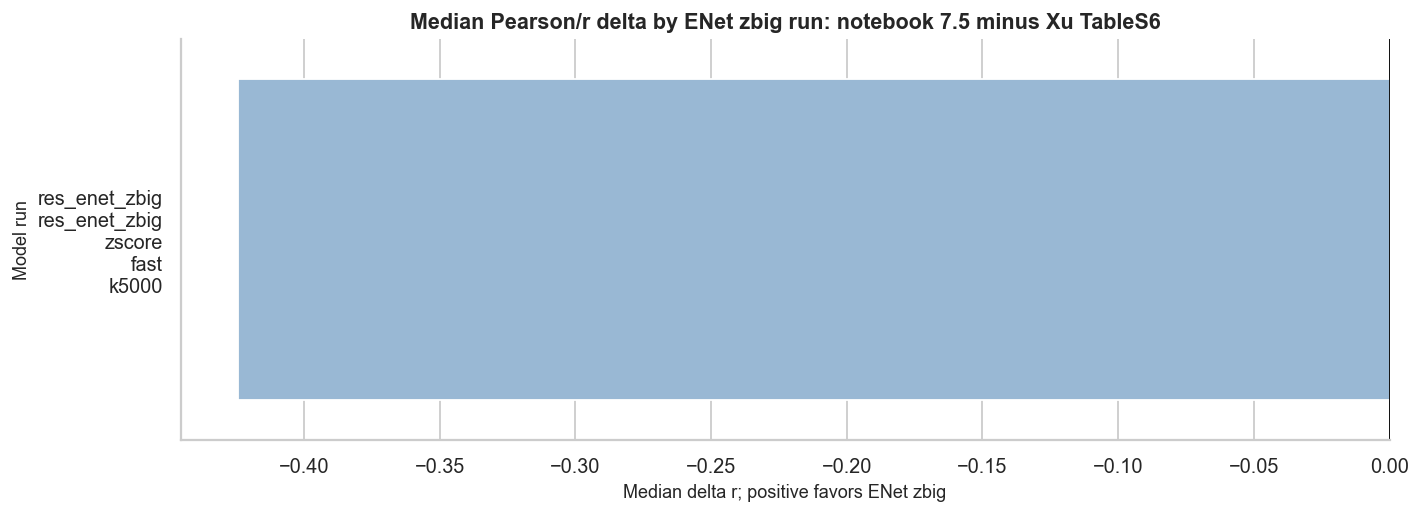

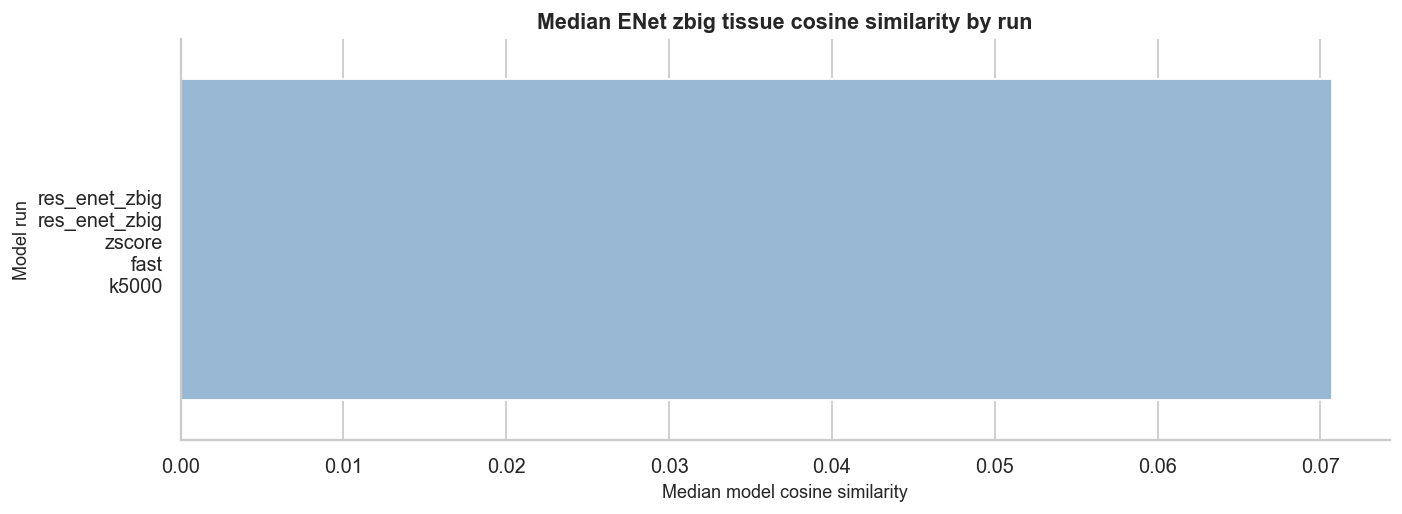

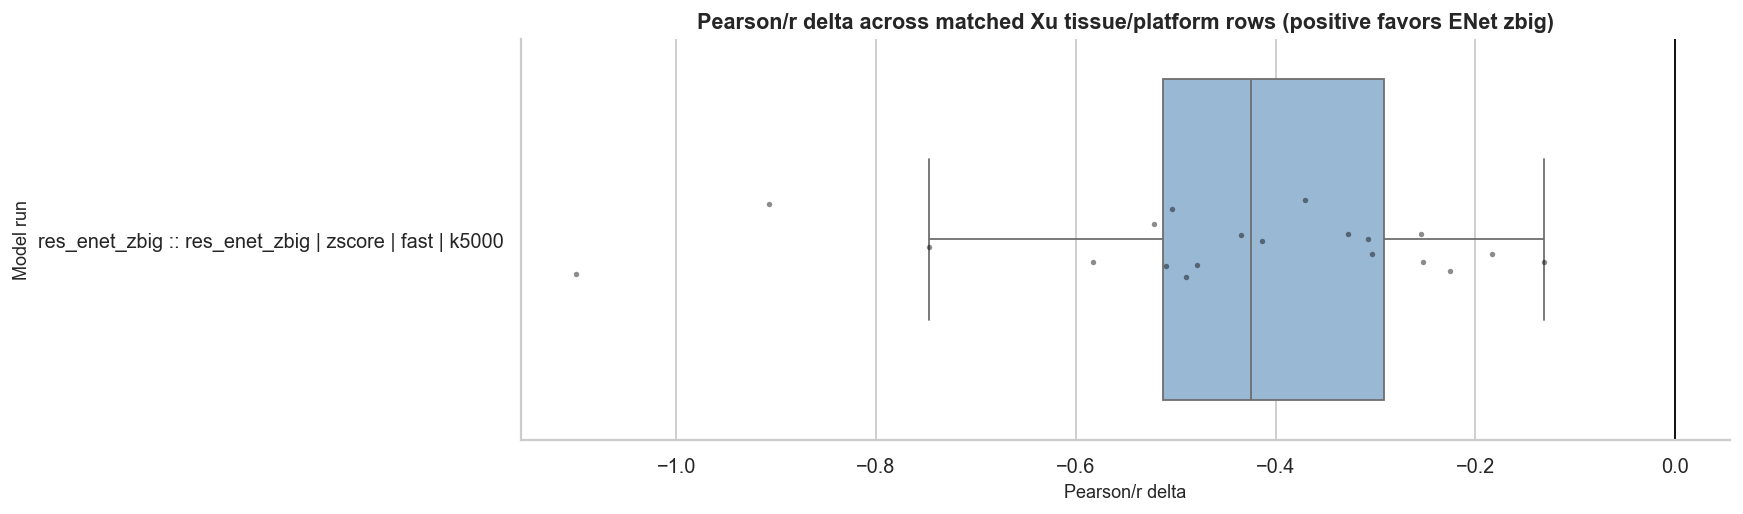

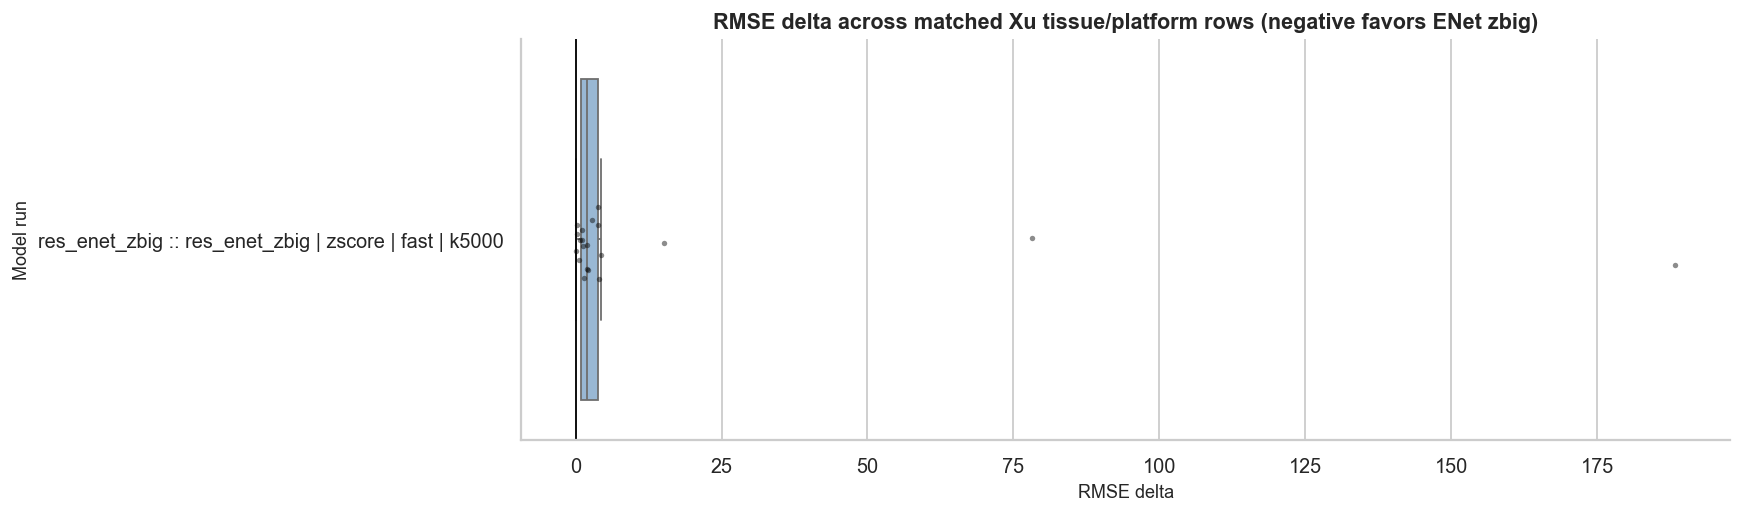

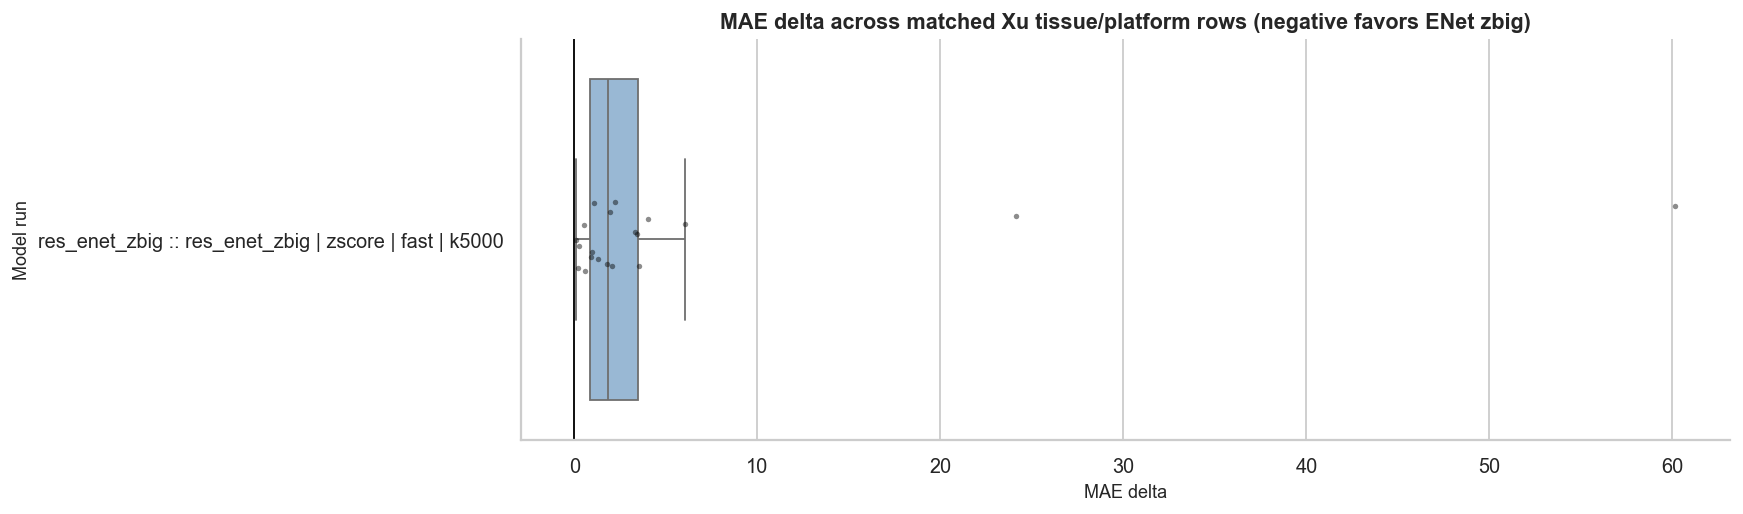

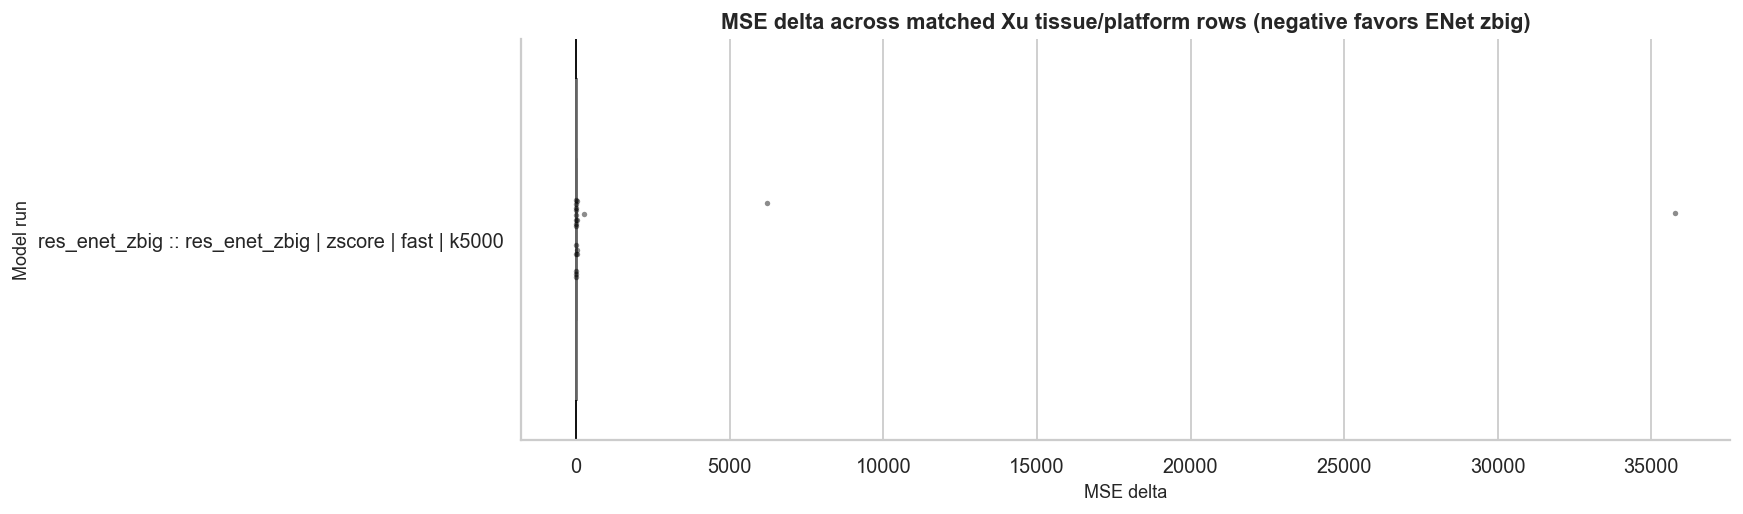

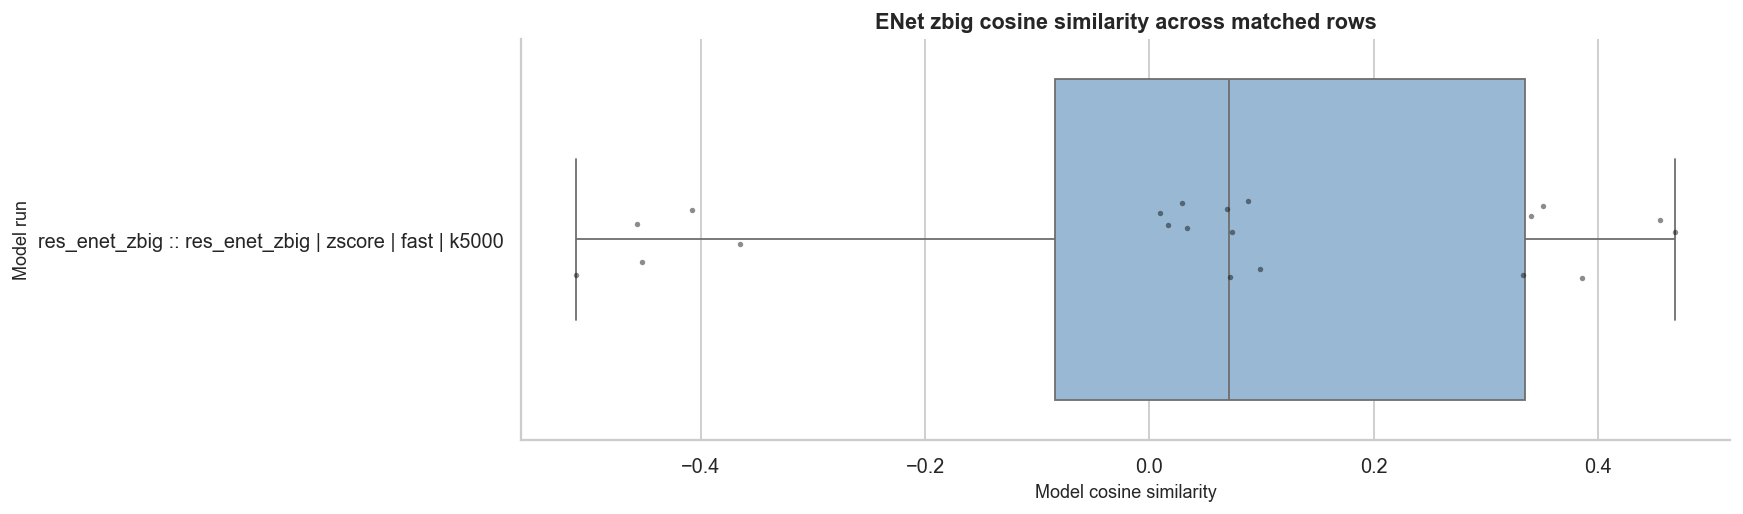

In [6]:

plot_summary = comparison_summary.copy()
plot_summary["model_short"] = plot_summary["model_id"].astype(str).str.replace(" :: ", "\n", regex=False).str.replace(" | ", "\n", regex=False)

fig, ax = plt.subplots(figsize=(12, max(4, 0.38 * len(plot_summary))))
sns.barplot(data=plot_summary, y="model_short", x="median_delta_r", ax=ax, color="#8FB8DE")
ax.axvline(0, color="black", linewidth=1)
ax.set_title("Median Pearson/r delta by ENet zbig run: notebook 7.5 minus Xu TableS6")
ax.set_xlabel("Median delta r; positive favors ENet zbig")
ax.set_ylabel("Model run")
fig.savefig(FIG_DIR / "median_delta_r_by_run.png", bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(12, max(4, 0.38 * len(plot_summary))))
sns.barplot(data=plot_summary, y="model_short", x="median_model_cosine", ax=ax, color="#8FB8DE")
ax.set_title("Median ENet zbig tissue cosine similarity by run")
ax.set_xlabel("Median model cosine similarity")
ax.set_ylabel("Model run")
fig.savefig(FIG_DIR / "median_model_cosine_by_run.png", bbox_inches="tight")
plt.show()

for metric, label, better, ascending in [
    ("delta_r", "Pearson/r delta", "positive favors ENet zbig", False),
    ("delta_rmse", "RMSE delta", "negative favors ENet zbig", True),
    ("delta_mae", "MAE delta", "negative favors ENet zbig", True),
    ("delta_mse", "MSE delta", "negative favors ENet zbig", True),
]:
    sub = matched.dropna(subset=[metric]).copy()
    if sub.empty:
        print(f"Skipping {label}: no finite values.")
        continue
    order = sub.groupby("model_id")[metric].median().sort_values(ascending=ascending).index.tolist()
    fig, ax = plt.subplots(figsize=(12, max(4, 0.38 * len(order))))
    sns.boxplot(data=sub, y="model_id", x=metric, order=order, showfliers=False, ax=ax, color="#8FB8DE")
    sns.stripplot(data=sub, y="model_id", x=metric, order=order, size=3, alpha=0.45, ax=ax, color="black")
    ax.axvline(0, color="black", linewidth=1)
    ax.set_title(f"{label} across matched Xu tissue/platform rows ({better})")
    ax.set_xlabel(label)
    ax.set_ylabel("Model run")
    fig.savefig(FIG_DIR / f"box_{metric}_by_run.png", bbox_inches="tight")
    plt.show()

# Cosine: compare to Xu only if Xu has cosine; otherwise show model cosine distribution.
if has_xu_cosine:
    cosine_metric = "delta_cosine"
    cosine_label = "Cosine delta"
    cosine_title = "Cosine delta across matched rows; positive favors ENet zbig"
else:
    cosine_metric = "model_cosine"
    cosine_label = "Model cosine similarity"
    cosine_title = "ENet zbig cosine similarity across matched rows"

sub = matched.dropna(subset=[cosine_metric]).copy()
if not sub.empty:
    order = sub.groupby("model_id")[cosine_metric].median().sort_values(ascending=False).index.tolist()
    fig, ax = plt.subplots(figsize=(12, max(4, 0.38 * len(order))))
    sns.boxplot(data=sub, y="model_id", x=cosine_metric, order=order, showfliers=False, ax=ax, color="#8FB8DE")
    sns.stripplot(data=sub, y="model_id", x=cosine_metric, order=order, size=3, alpha=0.45, ax=ax, color="black")
    if has_xu_cosine:
        ax.axvline(0, color="black", linewidth=1)
    ax.set_title(cosine_title)
    ax.set_xlabel(cosine_label)
    ax.set_ylabel("Model run")
    fig.savefig(FIG_DIR / f"box_{cosine_metric}_by_run.png", bbox_inches="tight")
    plt.show()


## 6. Best-run detailed plots

Focused plots for best median-Pearson-delta ENet zbig run: res_enet_zbig :: res_enet_zbig | zscore | fast | k5000


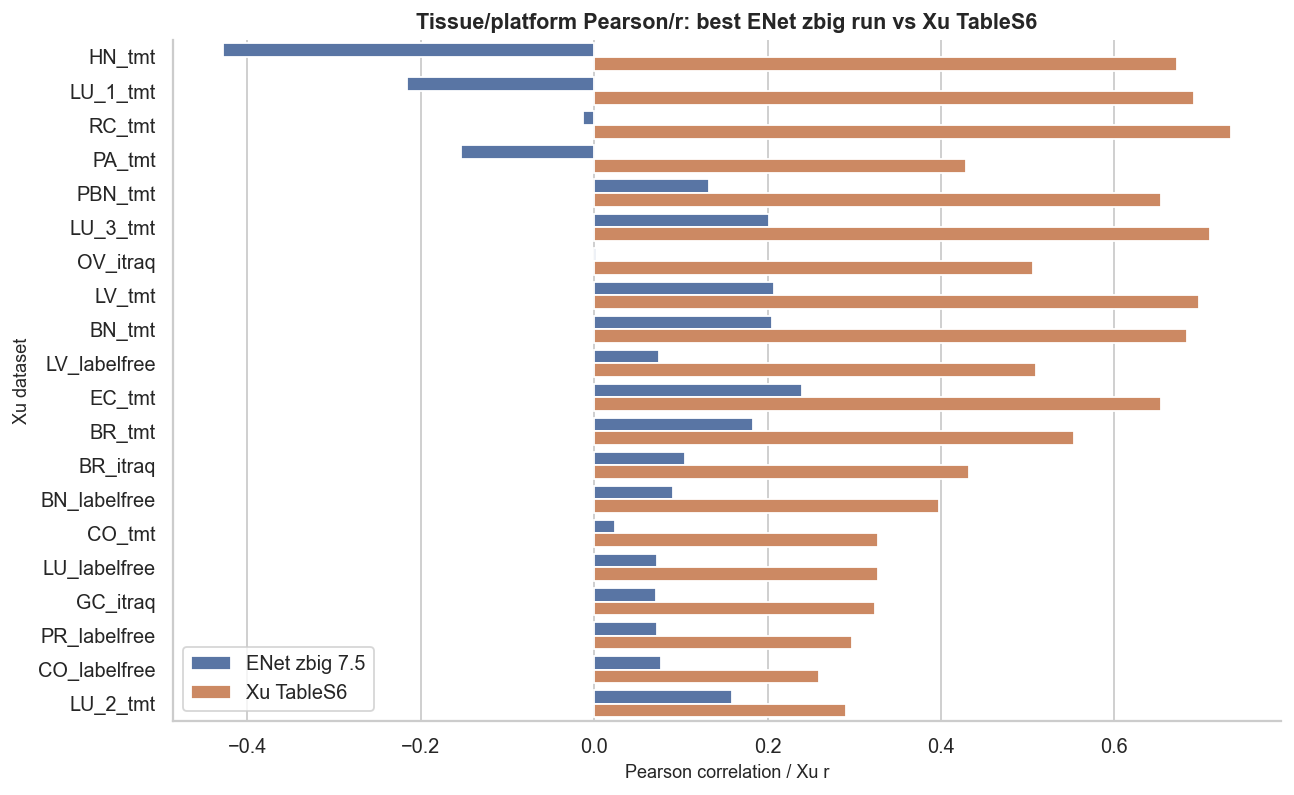

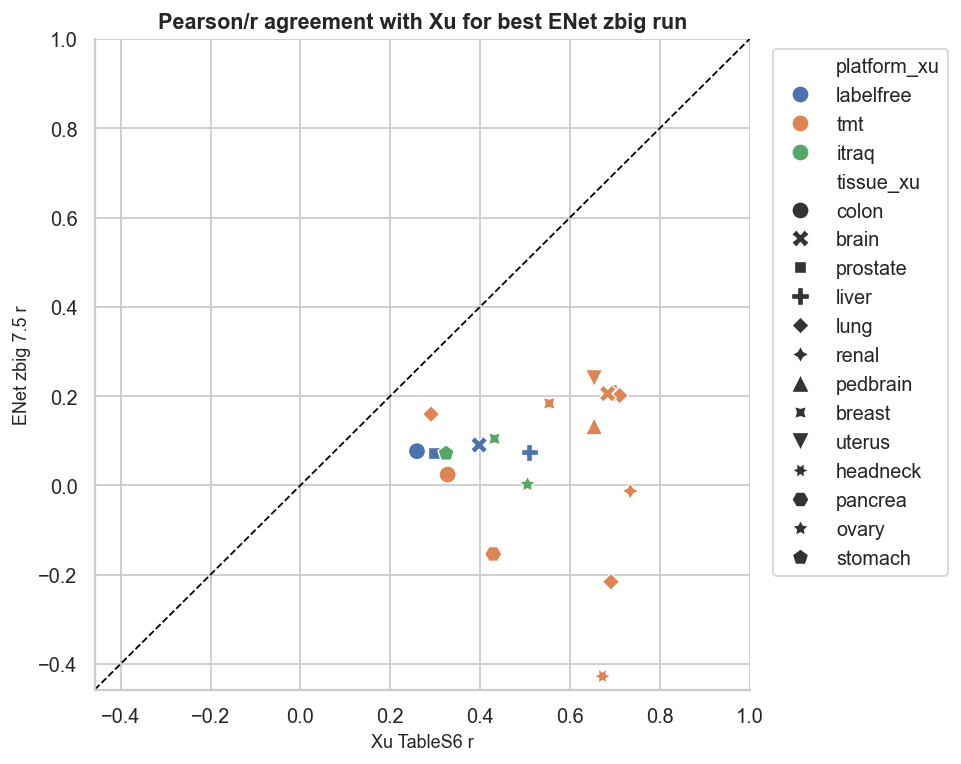

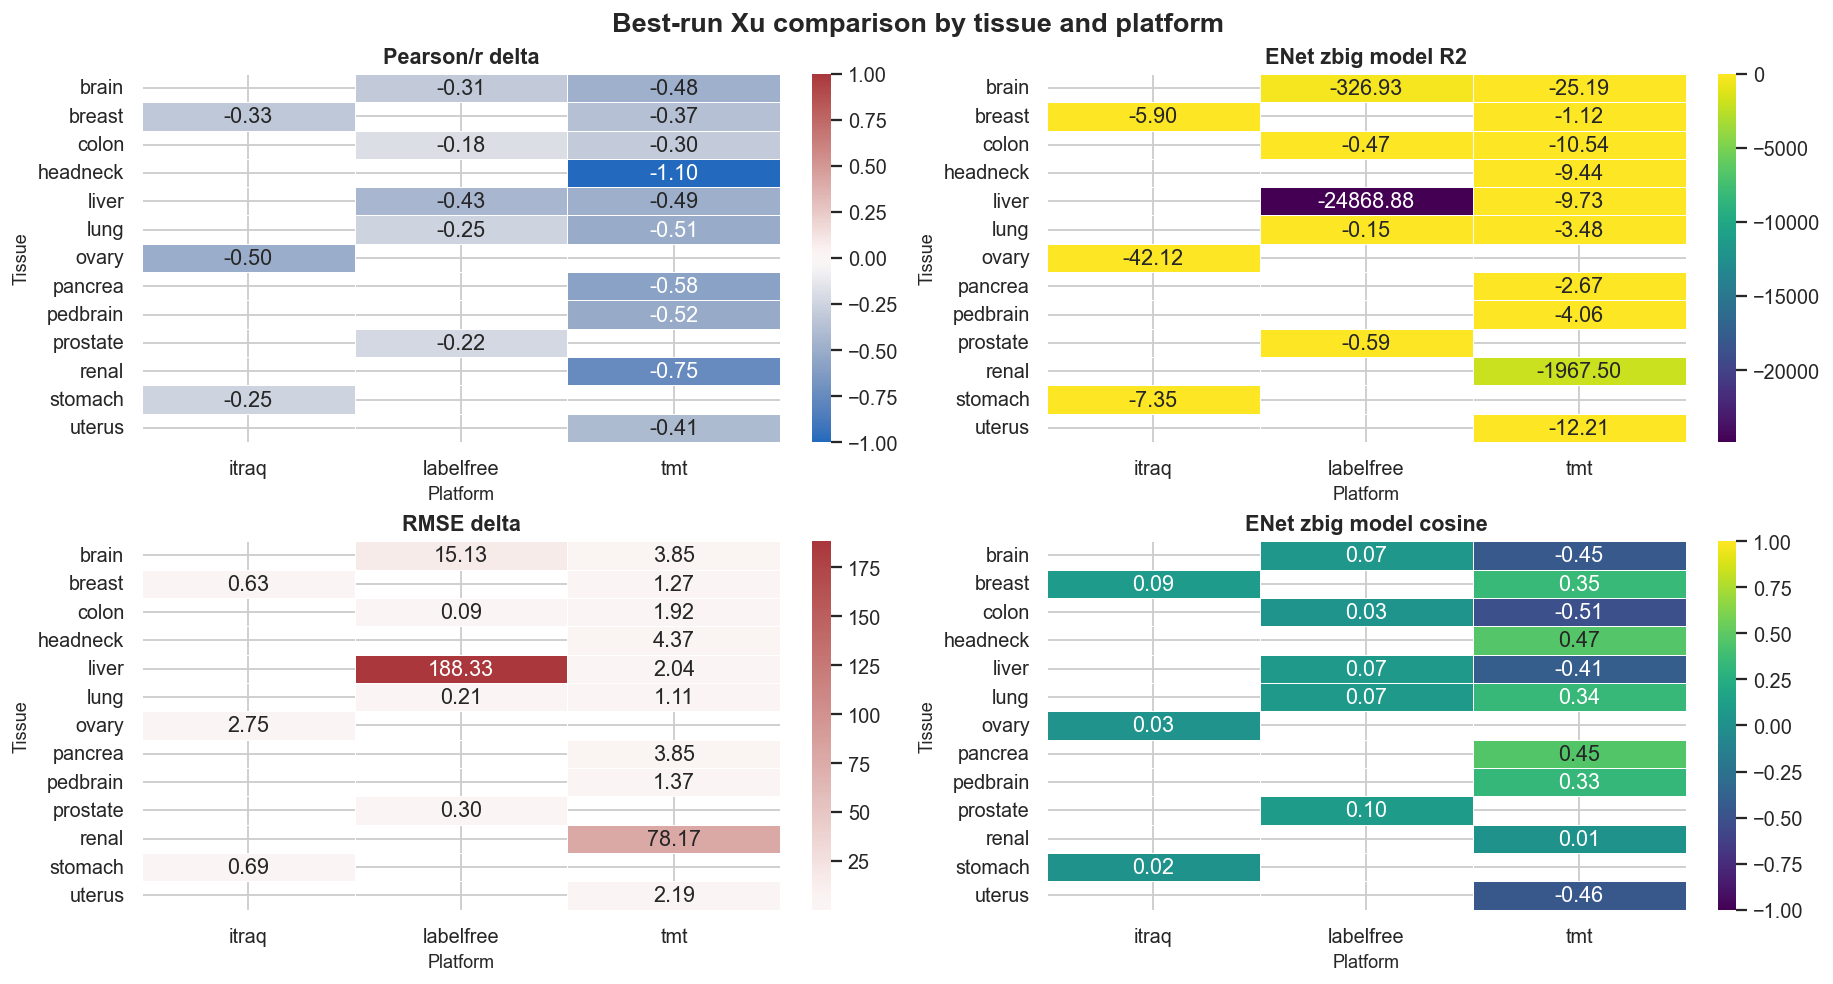

In [7]:

best_model_id = comparison_summary.iloc[0]["model_id"]
best = matched[matched["model_id"].eq(best_model_id)].copy()
print("Focused plots for best median-Pearson-delta ENet zbig run:", best_model_id)

plot_order = best.sort_values("delta_r", ascending=True)["ShortName_xu"].tolist()

long_r = best[["ShortName_xu", "platform_xu", "tissue_xu", "model_r", "xu_r"]].melt(
    id_vars=["ShortName_xu", "platform_xu", "tissue_xu"],
    value_vars=["model_r", "xu_r"],
    var_name="source",
    value_name="r",
)
long_r["source"] = long_r["source"].map({"model_r": "ENet zbig 7.5", "xu_r": "Xu TableS6"})
fig, ax = plt.subplots(figsize=(11, max(5, 0.34 * len(plot_order))))
sns.barplot(data=long_r, y="ShortName_xu", x="r", hue="source", order=plot_order, ax=ax)
ax.set_title("Tissue/platform Pearson/r: best ENet zbig run vs Xu TableS6")
ax.set_xlabel("Pearson correlation / Xu r")
ax.set_ylabel("Xu dataset")
ax.legend(title="")
fig.savefig(FIG_DIR / "best_run_r_vs_xu_barplot.png", bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(6.5, 6.5))
sns.scatterplot(data=best, x="xu_r", y="model_r", hue="platform_xu", style="tissue_xu", s=90, ax=ax)
finite_vals = pd.concat([best["xu_r"], best["model_r"]]).dropna()
if not finite_vals.empty:
    lo = min(-0.05, finite_vals.min() - 0.03)
    hi = max(1.0, finite_vals.max() + 0.03)
    ax.plot([lo, hi], [lo, hi], color="black", linewidth=1, linestyle="--")
    ax.set_xlim(lo, hi)
    ax.set_ylim(lo, hi)
ax.set_title("Pearson/r agreement with Xu for best ENet zbig run")
ax.set_xlabel("Xu TableS6 r")
ax.set_ylabel("ENet zbig 7.5 r")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", frameon=True)
fig.savefig(FIG_DIR / "best_run_r_scatter_vs_xu.png", bbox_inches="tight")
plt.show()

cosine_heat_metric = "delta_cosine" if has_xu_cosine else "model_cosine"
cosine_heat_title = "Cosine delta" if has_xu_cosine else "ENet zbig model cosine"
metric_specs = [
    ("delta_r", "Pearson/r delta", "vlag", -1, 1, 0),
    ("model_r2", "ENet zbig model R2", "viridis", None, 1, None),
    ("delta_rmse", "RMSE delta", "vlag", None, None, 0),
    (cosine_heat_metric, cosine_heat_title, "viridis" if not has_xu_cosine else "vlag", -1 if not has_xu_cosine else None, 1 if not has_xu_cosine else None, 0 if has_xu_cosine else None),
]
fig, axes = plt.subplots(2, 2, figsize=(14, max(6, 0.42 * best["tissue_xu"].nunique() + 2.0)), constrained_layout=True)
fig.suptitle("Best-run Xu comparison by tissue and platform", fontsize=15, fontweight="bold")
for ax, (metric, title, cmap, vmin, vmax, center) in zip(axes.ravel(), metric_specs):
    if metric not in best.columns:
        ax.axis("off")
        ax.set_title(f"{title}\nnot available")
        continue
    pivot = best.pivot_table(index="tissue_xu", columns="platform_xu", values=metric, aggfunc="median")
    sns.heatmap(pivot, ax=ax, cmap=cmap, center=center, linewidths=0.4, linecolor="white", annot=True, fmt=".2f", vmin=vmin, vmax=vmax)
    ax.set_title(title)
    ax.set_xlabel("Platform")
    ax.set_ylabel("Tissue")
fig.savefig(FIG_DIR / "best_run_heatmaps_with_cosine.png", bbox_inches="tight")
plt.show()


## 7. Error metrics and cosine plots for best run

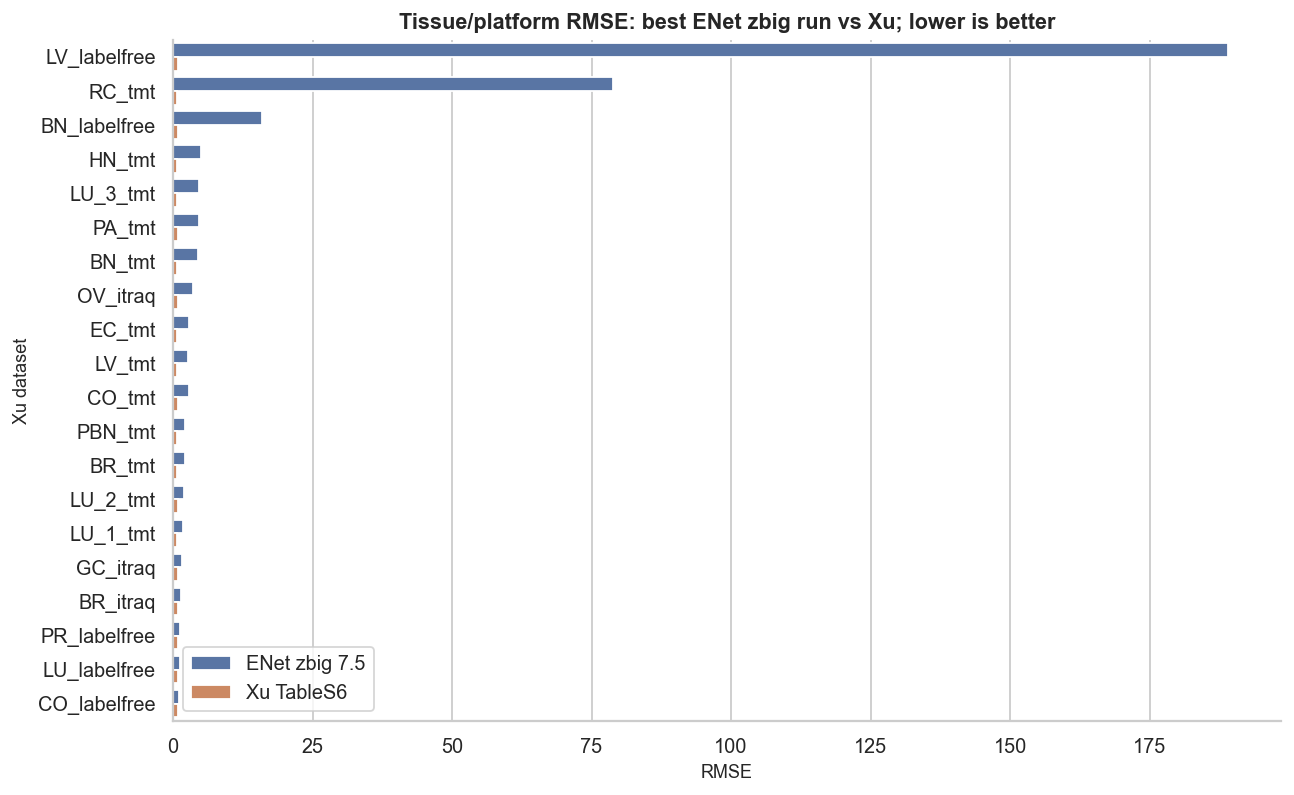

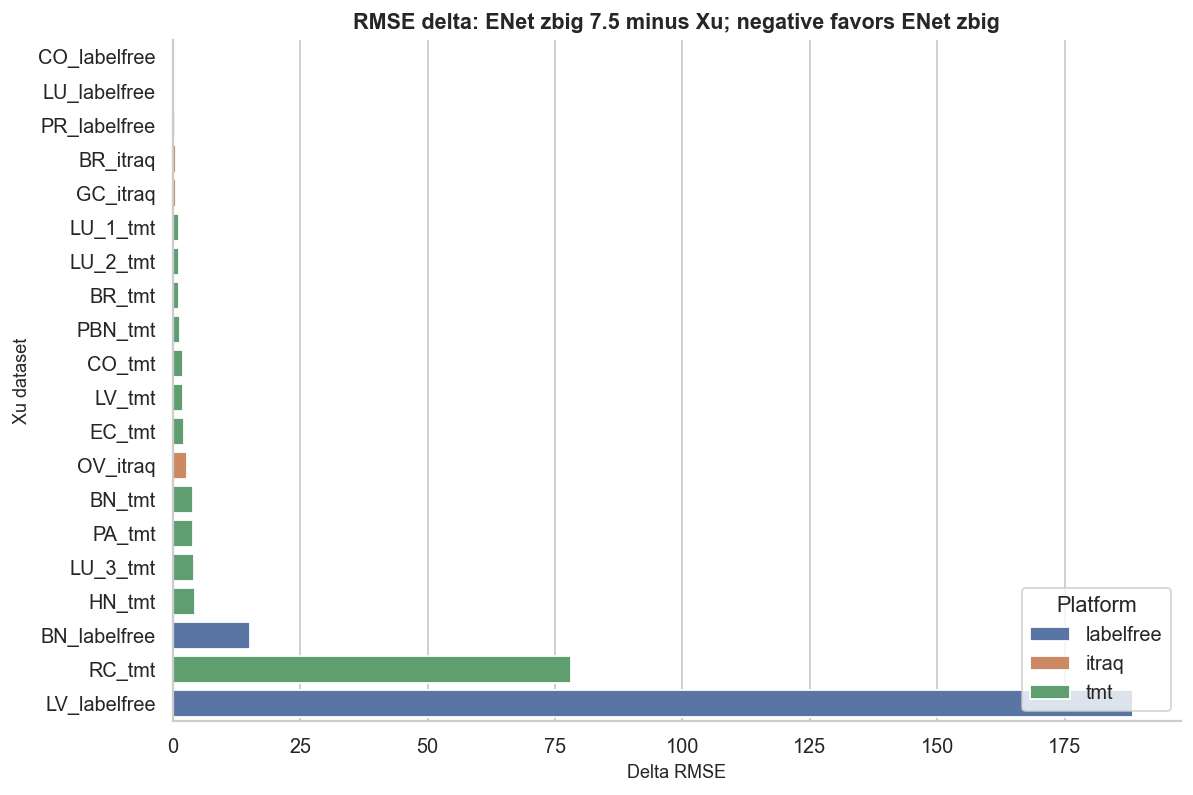

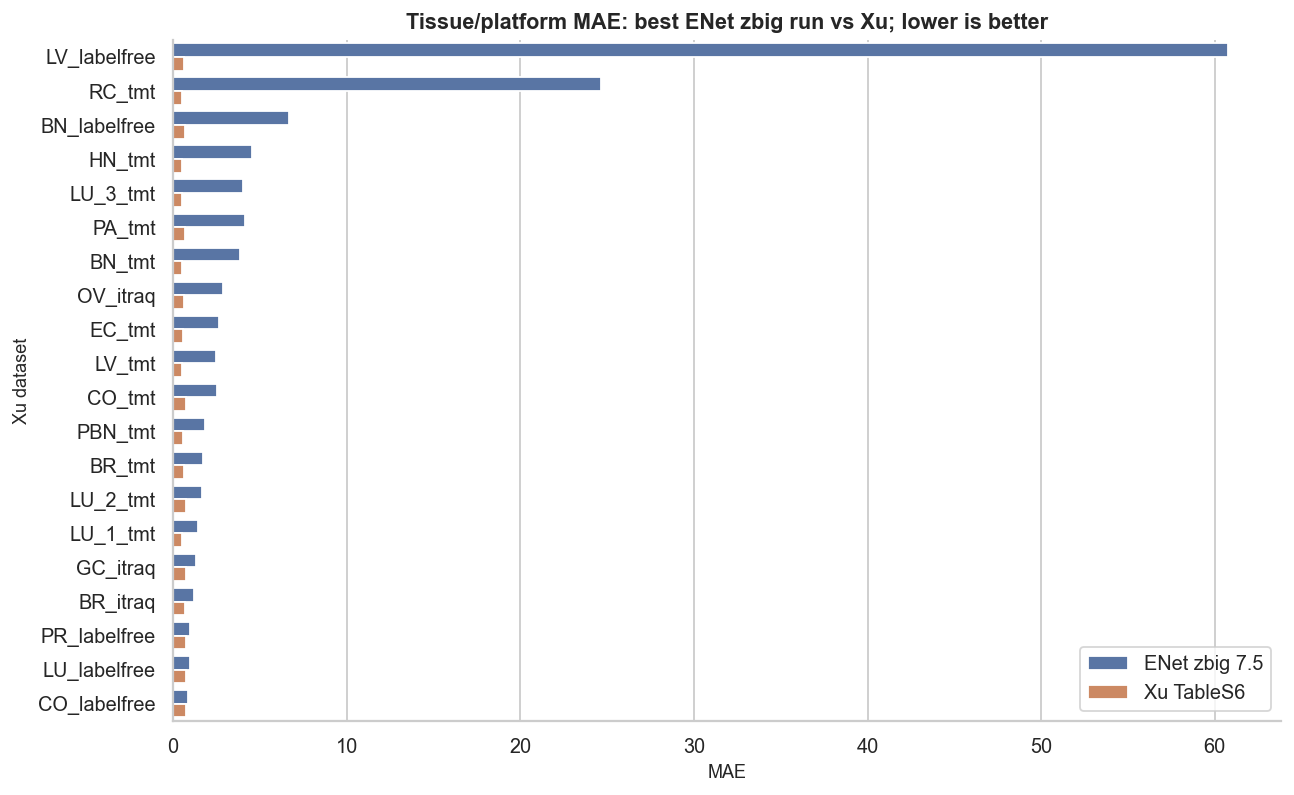

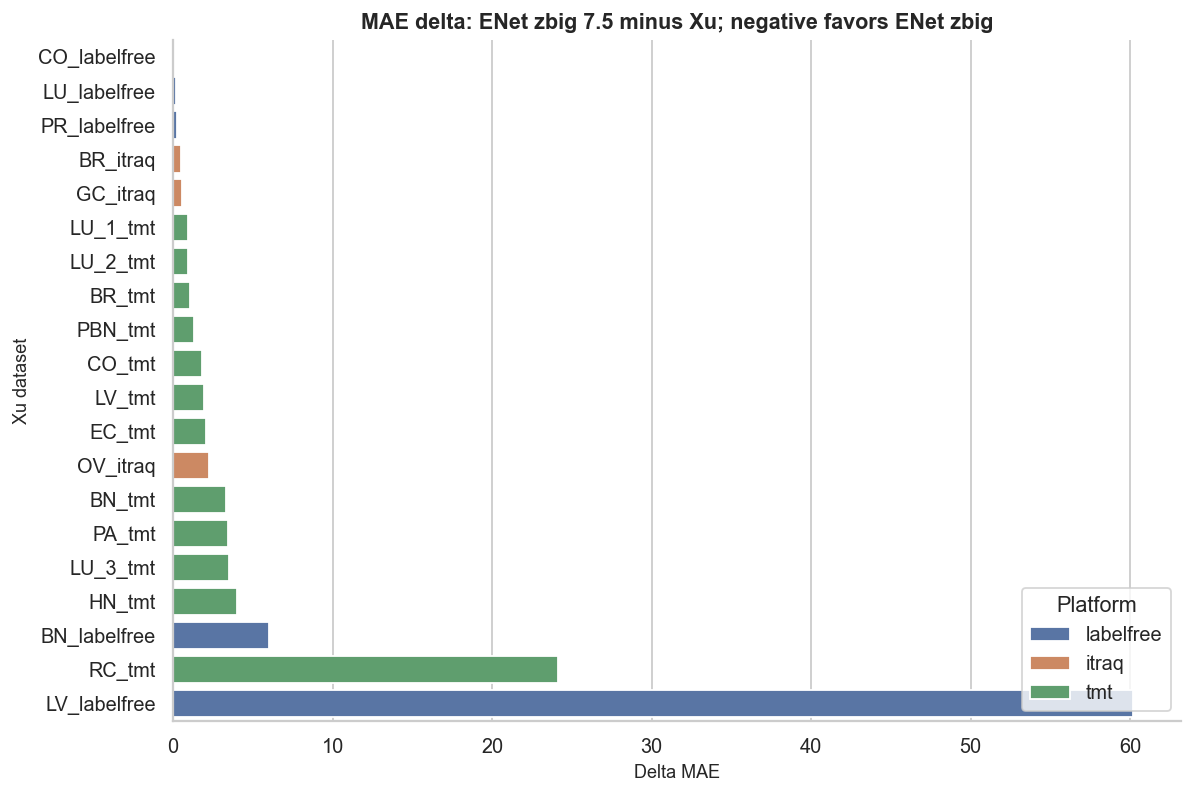

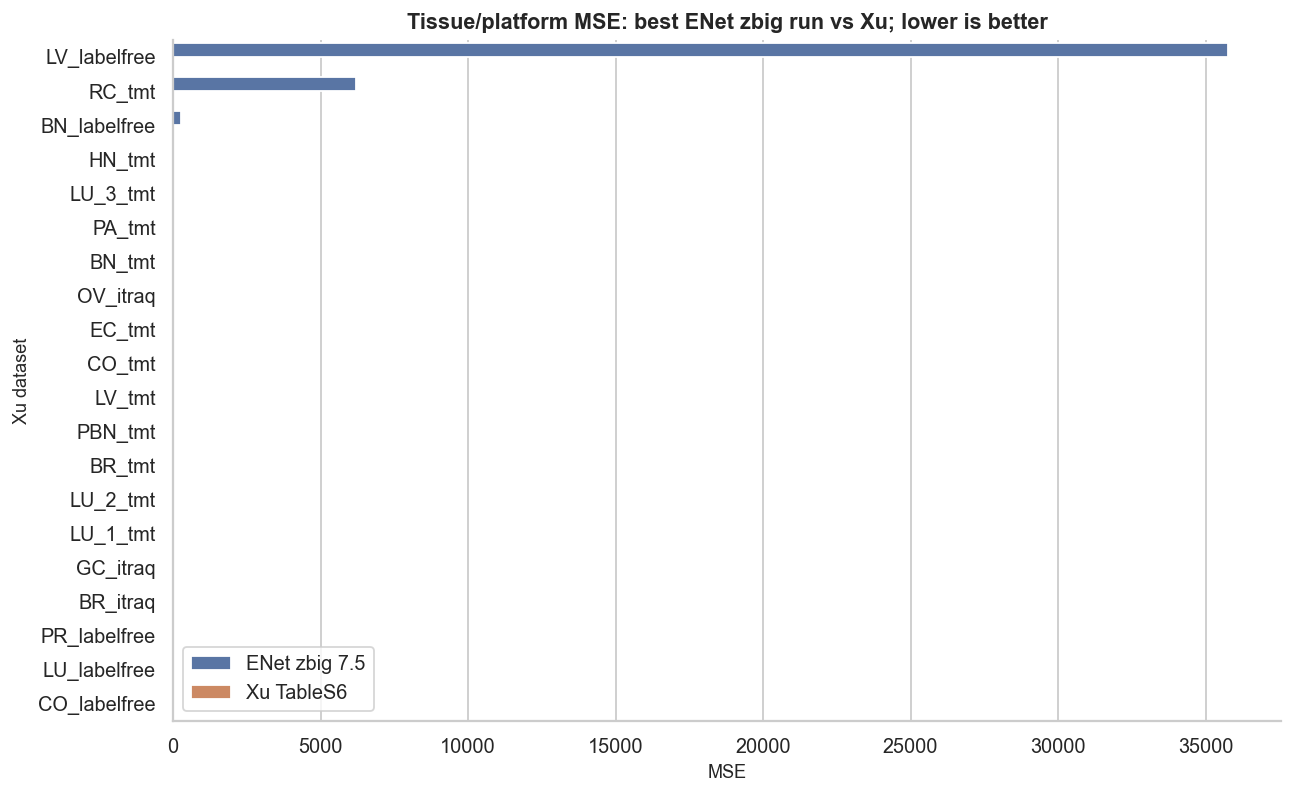

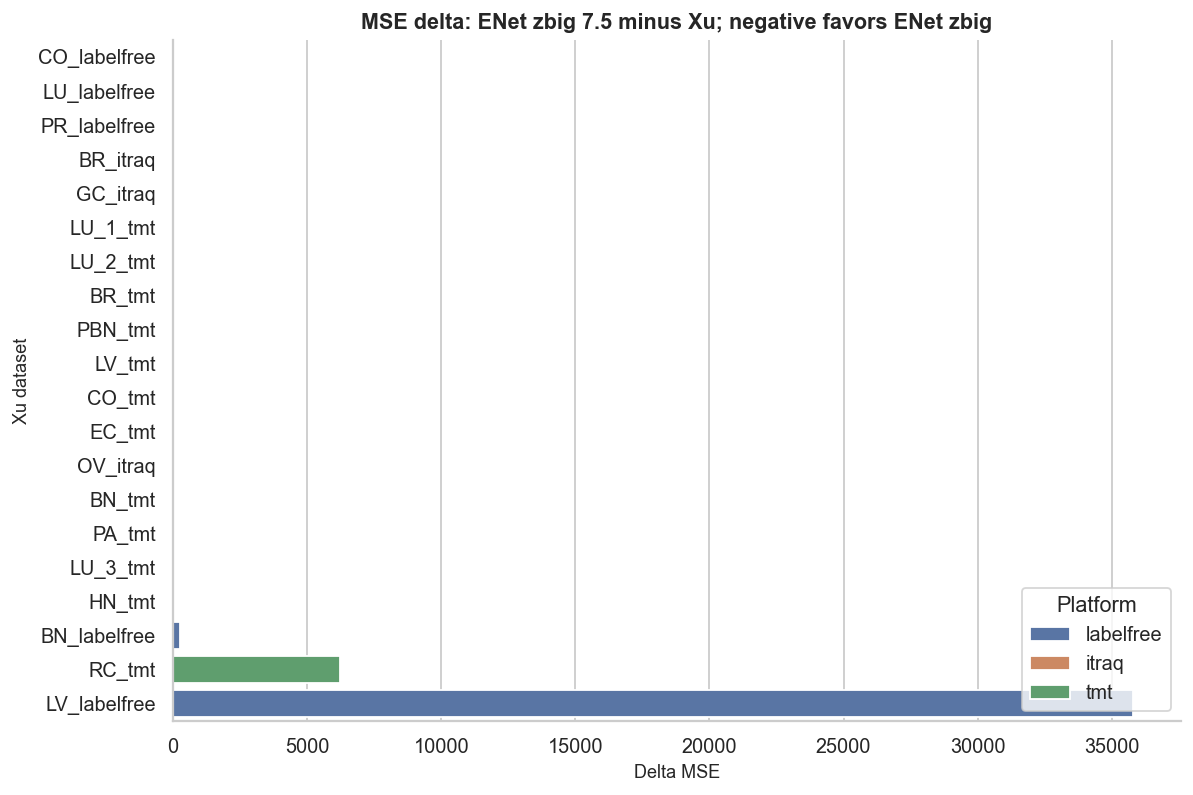

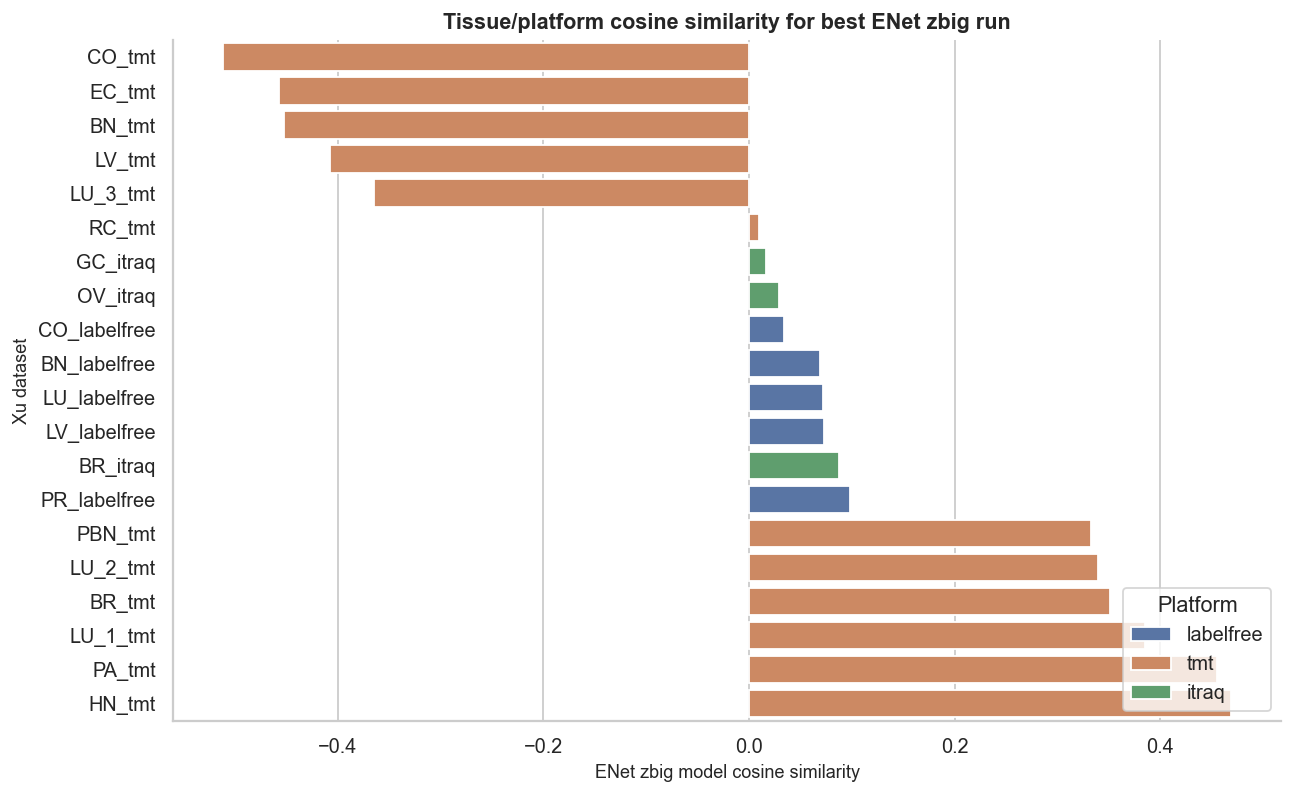

In [8]:

for model_col, xu_col, delta_col, label in [
    ("model_rmse", "xu_rmse", "delta_rmse", "RMSE"),
    ("model_mae", "xu_mae", "delta_mae", "MAE"),
    ("model_mse", "xu_mse", "delta_mse", "MSE"),
]:
    sub = best.dropna(subset=[model_col, xu_col]).copy()
    if sub.empty:
        print(f"Skipping {label}: no finite matched values.")
        continue
    order = sub.sort_values(delta_col, ascending=False)["ShortName_xu"].tolist()
    long = sub[["ShortName_xu", "platform_xu", "tissue_xu", model_col, xu_col]].melt(
        id_vars=["ShortName_xu", "platform_xu", "tissue_xu"],
        value_vars=[model_col, xu_col],
        var_name="source",
        value_name=label,
    )
    long["source"] = long["source"].map({model_col: "ENet zbig 7.5", xu_col: "Xu TableS6"})
    fig, ax = plt.subplots(figsize=(11, max(5, 0.34 * len(order))))
    sns.barplot(data=long, y="ShortName_xu", x=label, hue="source", order=order, ax=ax)
    ax.set_title(f"Tissue/platform {label}: best ENet zbig run vs Xu; lower is better")
    ax.set_xlabel(label)
    ax.set_ylabel("Xu dataset")
    ax.legend(title="")
    fig.savefig(FIG_DIR / f"best_run_{label.lower()}_vs_xu.png", bbox_inches="tight")
    plt.show()

    fig, ax = plt.subplots(figsize=(10, max(5, 0.34 * len(order))))
    sns.barplot(data=sub.sort_values(delta_col, ascending=True), y="ShortName_xu", x=delta_col, hue="platform_xu", dodge=False, ax=ax)
    ax.axvline(0, color="black", linewidth=1)
    ax.set_title(f"{label} delta: ENet zbig 7.5 minus Xu; negative favors ENet zbig")
    ax.set_xlabel(f"Delta {label}")
    ax.set_ylabel("Xu dataset")
    ax.legend(title="Platform", loc="lower right")
    fig.savefig(FIG_DIR / f"best_run_delta_{label.lower()}.png", bbox_inches="tight")
    plt.show()

# Cosine detailed plot.
sub = best.dropna(subset=["model_cosine"]).copy()
if not sub.empty:
    order = sub.sort_values("model_cosine", ascending=True)["ShortName_xu"].tolist()
    fig, ax = plt.subplots(figsize=(11, max(5, 0.34 * len(order))))
    sns.barplot(data=sub, y="ShortName_xu", x="model_cosine", hue="platform_xu", dodge=False, order=order, ax=ax)
    ax.set_title("Tissue/platform cosine similarity for best ENet zbig run")
    ax.set_xlabel("ENet zbig model cosine similarity")
    ax.set_ylabel("Xu dataset")
    ax.legend(title="Platform", loc="lower right")
    fig.savefig(FIG_DIR / "best_run_model_cosine_by_tissue.png", bbox_inches="tight")
    plt.show()


## 8. Unmatched diagnostics

In [9]:

print("Unmatched Xu rows. These need a matching 7.5 tissue/platform or ShortName if they should be compared:")
unmatched_xu_cols = [c for c in ["ShortName", "tissue", "platform", "tissue_key", "platform_key", "shortname_key", "join_key", "samples", "totalprotein"] if c in unmatched_xu.columns]
display(unmatched_xu[unmatched_xu_cols].sort_values([c for c in ["platform", "tissue"] if c in unmatched_xu_cols]) if len(unmatched_xu) else pd.DataFrame(columns=unmatched_xu_cols))

print("Unmatched ENet zbig tissue/model rows. These are available from 7.5 but not present in Xu TableS6:")
unmatched_model_cols = [c for c in ["ShortName", "tissue", "platform", "model_id", "source_folder", "run_label", "tissue_key", "platform_key", "shortname_key", "join_key", "samples", "common", "r", "rmse", "mae", "model_cosine", "test_cosine_similarity"] if c in unmatched_model.columns]
display(unmatched_model[unmatched_model_cols].sort_values([c for c in ["model_id", "platform", "tissue"] if c in unmatched_model_cols]) if len(unmatched_model) else pd.DataFrame(columns=unmatched_model_cols))


Unmatched Xu rows. These need a matching 7.5 tissue/platform or ShortName if they should be compared:


,ShortName,tissue,platform,tissue_key,platform_key,shortname_key,join_key,samples,totalprotein


Unmatched ENet zbig tissue/model rows. These are available from 7.5 but not present in Xu TableS6:


,ShortName,tissue,platform,model_id,source_folder,run_label,tissue_key,platform_key,shortname_key,join_key,samples,common,r,rmse,mae,model_cosine,test_cosine_similarity


## 9. Exports

In [10]:

xu.to_csv(OUT_DIR / "xu_tableS6_summary_clean.csv", index=False)
model.to_csv(OUT_DIR / "enet_zbig_tissue_metrics_tableS6_format_used.csv", index=False)
model_unique.to_csv(OUT_DIR / "enet_zbig_tissue_metrics_unique_by_run.csv", index=False)
comparison.to_csv(OUT_DIR / "enet_zbig_tissue_vs_xu_all_rows.csv", index=False)
matched.to_csv(OUT_DIR / "enet_zbig_tissue_vs_xu_matched.csv", index=False)
unmatched_xu.to_csv(OUT_DIR / "unmatched_xu_rows_for_enet_zbig_tissue_comparison.csv", index=False)
unmatched_model.to_csv(OUT_DIR / "unmatched_enet_zbig_tissue_rows_for_xu_comparison.csv", index=False)
comparison_summary.to_csv(OUT_DIR / "enet_zbig_vs_xu_summary_by_model_run.csv", index=False)
best_by_r.to_csv(OUT_DIR / "best_enet_zbig_model_per_xu_row_by_r.csv", index=False)
best_by_rmse.to_csv(OUT_DIR / "best_enet_zbig_model_per_xu_row_by_rmse.csv", index=False)
best_by_cosine.to_csv(OUT_DIR / "best_enet_zbig_model_per_xu_row_by_cosine.csv", index=False)

print("Saved Xu comparison outputs to:", OUT_DIR)
for p in sorted(OUT_DIR.glob("*.csv")):
    print("-", p.name)
print("\nSaved figures to:", FIG_DIR)
for p in sorted(FIG_DIR.glob("*.png")):
    print("-", p.name)


Saved Xu comparison outputs to: C:\Users\hp\Desktop\new_pRNA\xu_enet_zbig_comparison_outputs
- best_enet_zbig_model_per_xu_row_by_cosine.csv
- best_enet_zbig_model_per_xu_row_by_r.csv
- best_enet_zbig_model_per_xu_row_by_rmse.csv
- enet_zbig_tissue_metrics_tableS6_format_used.csv
- enet_zbig_tissue_metrics_unique_by_run.csv
- enet_zbig_tissue_vs_xu_all_rows.csv
- enet_zbig_tissue_vs_xu_matched.csv
- enet_zbig_vs_xu_summary_by_model_run.csv
- unmatched_enet_zbig_tissue_rows_for_xu_comparison.csv
- unmatched_xu_rows_for_enet_zbig_tissue_comparison.csv
- xu_tableS6_summary_clean.csv

Saved figures to: C:\Users\hp\Desktop\new_pRNA\xu_enet_zbig_comparison_outputs\figures
- best_run_delta_mae.png
- best_run_delta_mse.png
- best_run_delta_rmse.png
- best_run_heatmaps_with_cosine.png
- best_run_mae_vs_xu.png
- best_run_model_cosine_by_tissue.png
- best_run_mse_vs_xu.png
- best_run_r_scatter_vs_xu.png
- best_run_r_vs_xu_barplot.png
- best_run_rmse_vs_xu.png
- box_delta_mae_by_run.png
- box_delt